# Generative Adversarial Networks: an interactive lab

In this lab you will **watch** GANs learn, **break** them on purpose, and **explore** what a trained generator has learned.
All the code is complete: your job is to run it, play with the controls, and answer the questions in the 🔎 boxes.

| Part | What you do | Training time |
|---|---|---|
| **0. Setup** | Run once | – |
| **1. The adversarial game in 2D** | Train tiny GANs live on toy data: equilibrium, vanishing gradients, mode collapse, WGAN-GP | seconds per run |
| **2. DCGAN on MNIST** | Train a convolutional GAN with a live dashboard, then replay the training | ~1–2 min (GPU), ~5–10 min (CPU) |
| **3. Exploring the generator** | Latent space: interpolation, arithmetic, single dimensions, inside the network | – |
| **4. Diagnosing mode collapse** | Use a digit classifier to measure what the GAN generates | ~30 s |
| **5. Conditional GAN** *(optional)* | Choose which digit to generate | ~1–2 min (GPU) |

**Running it.** The notebook works inside **the folder it is stored in**: the MNIST data (`data/`) and the trained models (`gan_lab_outputs/`) are saved there, so if you rerun it later the models are loaded instead of trained again.
- **Google Colab:** put the folder with this notebook in your Google Drive and open the notebook from there. In the first code cell, set `COLAB_LAB_DIR` to that folder's path in Drive (it is mounted at `/content/drive/MyDrive/...`). Then `Runtime → Change runtime type → T4 GPU`, and run the cells in order (or `Runtime → Run all`). Colab will ask for permission to access your Drive.
- **Locally:** `pip install torch torchvision matplotlib ipywidgets`, then open the notebook from its folder in Jupyter Lab/Notebook or VS Code. A GPU (CUDA or Apple Silicon) is used automatically if available; everything also runs on CPU.

The interactive controls are *widgets*: they only work while the notebook is running. If you reopen the notebook, run the cells again.

**References.** [1] Goodfellow et al., *Generative Adversarial Nets*, 2014. [2] Radford et al., *Unsupervised Representation Learning with Deep Convolutional GANs* (DCGAN), 2015. [3] Arjovsky et al., *Wasserstein GAN*, 2017. [4] Gulrajani et al., *Improved Training of Wasserstein GANs* (WGAN-GP), 2017. [5] Mirza & Osindero, *Conditional GANs*, 2014. [6] [ganhacks](https://github.com/soumith/ganhacks).

## 0. Setup

Run the two cells below. The first one moves into the notebook's folder (mounting Google Drive in Colab), checks your environment and picks the device; the second defines some small plotting helpers (you don't need to read them).

**Colab users:** edit `COLAB_LAB_DIR` in the next cell first.

In [1]:
%matplotlib inline
import sys, io, math, time, os, random, traceback

# Colab only: the Google Drive folder that contains this notebook (edit this line)
COLAB_LAB_DIR = "/content/drive/MyDrive/Aprendizaje Profundo 26-27"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive, output
    drive.mount("/content/drive")
    if not os.path.isdir(COLAB_LAB_DIR):
        raise FileNotFoundError(f"'{COLAB_LAB_DIR}' does not exist in your Drive. Set COLAB_LAB_DIR to the folder "
                                "that contains this notebook (browse it in the Files panel on the left).")
    os.chdir(COLAB_LAB_DIR)
    output.enable_custom_widget_manager()
# Locally, Jupyter and VS Code already start in the notebook's folder.
LAB_DIR = os.getcwd()

missing = []
for pkg in ["torch", "torchvision", "matplotlib", "ipywidgets", "numpy", "PIL"]:
    try:
        __import__(pkg)
    except ImportError:
        missing.append(pkg if pkg != "PIL" else "pillow")
if missing:
    raise ImportError(f"Missing packages: {missing}.  Install them with:  pip install {' '.join(missing)}")

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.utils as vutils
import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from matplotlib.colors import hsv_to_rgb
import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image as PILImage

if torch.cuda.is_available():
    device = torch.device("cuda")
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

OUT_DIR = os.path.join(LAB_DIR, "gan_lab_outputs")   # trained models are saved here so you don't need to retrain
DATA_DIR = os.path.join(LAB_DIR, "data")              # MNIST is downloaded here once
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed(0)
print(f"PyTorch {torch.__version__} | device: {device} | running in {'Colab' if IN_COLAB else 'local Jupyter'}")
print(f"Working folder: {LAB_DIR}")
if device.type == "cpu":
    print("No GPU found: everything works, Part 2 training will just take a few minutes.")

PyTorch 2.14.1+cu126 | device: cuda | running in local Jupyter
Working folder: C:\Users\javia\Documents\GitHub\deep-learning-lab02\Lab03


In [2]:
# ---- Plotting helpers: figures are rendered to PNG and shown in image widgets (smooth live updates) ----
def fig_to_png(fig, dpi=80):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight", facecolor="white")
    return buf.getvalue()

def tensor_grid_png(imgs, nrow=8, scale=3, pad=2):
    # imgs: (B,1,28,28) in [-1,1]  ->  PNG bytes of an upscaled grid (crisp pixels)
    grid = vutils.make_grid(imgs.detach().float().cpu(), nrow=nrow, padding=pad,
                            normalize=True, value_range=(-1, 1), pad_value=1.0)
    arr = (grid[0].clamp(0, 1).numpy() * 255).astype(np.uint8)
    im = PILImage.fromarray(arr)
    im = im.resize((im.width * scale, im.height * scale), PILImage.NEAREST)
    buf = io.BytesIO(); im.save(buf, format="PNG")
    return buf.getvalue()

def feature_grid_png(fmaps, nrow=8, scale=4, pad=1):
    # fmaps: (C,H,W) feature maps, each normalised on its own
    grid = vutils.make_grid(fmaps.detach().float().cpu().unsqueeze(1), nrow=nrow, padding=pad,
                            normalize=True, scale_each=True, pad_value=1.0)
    arr = (grid[0].clamp(0, 1).numpy() * 255).astype(np.uint8)
    im = PILImage.fromarray(arr)
    im = im.resize((im.width * scale, im.height * scale), PILImage.NEAREST)
    buf = io.BytesIO(); im.save(buf, format="PNG")
    return buf.getvalue()

def smooth(y, k=25):
    y = np.asarray(y, dtype=float)
    if len(y) < k:
        return np.arange(len(y)), y
    return np.arange(k - 1, len(y)), np.convolve(y, np.ones(k) / k, mode="valid")

def on_change(update, *controls):
    # call update() now and whenever any of the controls changes
    for c in controls:
        c.observe(lambda change: update(), names="value")
    update()

def cap(title, widget):
    # a widget with a bold caption on top
    return widgets.VBox([widgets.HTML(f"<b>{title}</b>"), widget])

def safe(fn, log):
    # run a widget callback, showing errors instead of failing silently
    def wrapper(*args, **kwargs):
        try:
            return fn(*args, **kwargs)
        except Exception:
            with log:
                traceback.print_exc()
    return wrapper

print("helpers ready")

helpers ready


In [3]:
# ---- Static snapshots (added for the answers) ----
# The widgets only work while the kernel is running. The answer cells below also display static
# PNG copies of the relevant plots, so the results can be read in the saved notebook.
from IPython.display import Image as IPImage

def show_png(png, title=None):
    if title:
        display(widgets.HTML(f"<b>{title}</b>"))
    display(IPImage(data=png))

---
## 1. The adversarial game in 2D

Images live in spaces with hundreds of dimensions, which makes it hard to *see* what a GAN is doing. So we start with data in **2 dimensions**: each training example is just a point $(x_1, x_2)$, and the generator must learn to produce points with the same distribution.

The two players (slides: *Generative Adversarial Network, Goodfellow 2014*):

- **Generator** $G_\theta(z)$: takes noise $z \sim \mathcal{N}(0, I)$ and outputs a point $\tilde{x}$. We never write down its density $p_g$; we can only **sample** from it (implicit density model).
- **Discriminator** $D_\phi(x) \in (0,1)$: the probability that $x$ is **real**. It is a binary classifier trained with binary cross-entropy.

They play the minimax game
$$\min_G \max_D \; V(D,G) = \mathbb{E}_{x\sim p_{data}}\big[\log D(x)\big] + \mathbb{E}_{z\sim p_z}\big[\log(1-D(G(z)))\big].$$

For a fixed $G$, the optimal discriminator is $D^*(x) = \dfrac{p_{data}(x)}{p_{data}(x)+p_g(x)}$, and plugging it in, $G$ minimises $-\log 4 + 2\,\mathrm{JSD}(p_{data}\,\|\,p_g)$. The global optimum is $p_g = p_{data}$, where $D^*(x) = \tfrac12$ everywhere: **the discriminator can only guess.**

Below, both networks are small MLPs. In code, $D$ returns a *logit* $\ell$ and $D(x) = \sigma(\ell)$; working with logits is numerically safer (`softplus(-l)` $= -\log\sigma(\ell)$ and `softplus(l)` $= -\log(1-\sigma(\ell))$).

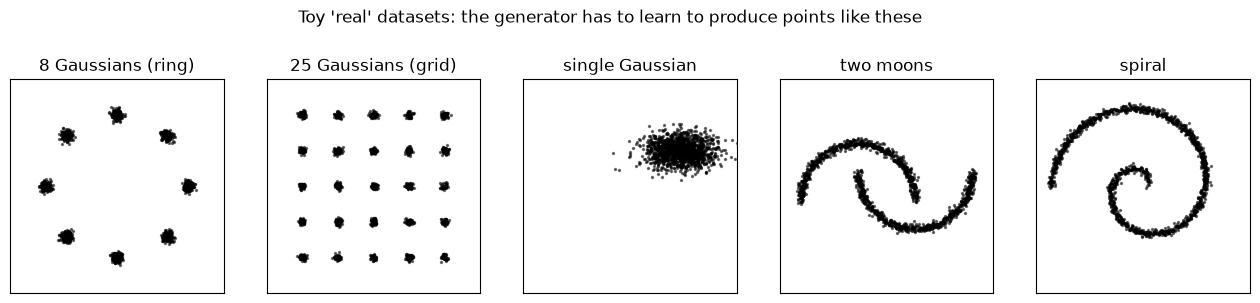

In [4]:
# ---------------- toy datasets ----------------
def _mixture(centers, n, std):
    centers = torch.tensor(centers, dtype=torch.float32)
    idx = torch.randint(len(centers), (n,))
    return centers[idx] + std * torch.randn(n, 2)

RING_CENTERS = [(2 * math.cos(2 * math.pi * k / 8), 2 * math.sin(2 * math.pi * k / 8)) for k in range(8)]
GRID_CENTERS = [(i, j) for i in (-2, -1, 0, 1, 2) for j in (-2, -1, 0, 1, 2)]
MODE_INFO = {"8 Gaussians (ring)": (RING_CENTERS, 0.08), "25 Gaussians (grid)": (GRID_CENTERS, 0.05)}

def sample_toy(name, n):
    if name == "8 Gaussians (ring)":
        return _mixture(RING_CENTERS, n, 0.08)
    if name == "25 Gaussians (grid)":
        return _mixture(GRID_CENTERS, n, 0.05)
    if name == "single Gaussian":
        return torch.tensor([1.4, 1.0]) + torch.randn(n, 2) * torch.tensor([0.5, 0.25])
    if name == "two moons":
        t = torch.rand(n) * math.pi
        upper = torch.rand(n) < 0.5
        x = torch.where(upper, torch.cos(t), 1 - torch.cos(t))
        y = torch.where(upper, torch.sin(t), 0.5 - torch.sin(t))
        pts = torch.stack([x - 0.5, y - 0.25], 1) * 1.6
        return pts + 0.06 * torch.randn(n, 2)
    if name == "spiral":
        t = torch.sqrt(torch.rand(n)) * 3 * math.pi
        pts = torch.stack([t * torch.cos(t), t * torch.sin(t)], 1) / (3 * math.pi) * 2.6
        return pts + 0.05 * torch.randn(n, 2)
    raise ValueError(name)

TOY_DATASETS = ["8 Gaussians (ring)", "25 Gaussians (grid)", "single Gaussian", "two moons", "spiral"]

fig, axes = plt.subplots(1, len(TOY_DATASETS), figsize=(16, 3.3))
for ax, name in zip(axes, TOY_DATASETS):
    p = sample_toy(name, 1500)
    ax.scatter(p[:, 0], p[:, 1], s=2, c="k", alpha=0.5)
    ax.set_title(name); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Toy 'real' datasets: the generator has to learn to produce points like these", y=1.03)
plt.show()

In [5]:
# ---------------- the two players ----------------
class ToyGenerator(nn.Module):
    def __init__(self, nz=2, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(nz, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 2))
    def forward(self, z):
        return self.net(z)

class ToyDiscriminator(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1))
    def forward(self, x):
        return self.net(x).view(-1)          # logit; D(x) = sigmoid(logit)  (for WGAN: critic value f(x))

# ---------------- the losses ----------------
def d_loss_fn(l_real, l_fake, loss_type):
    if loss_type == "WGAN-GP":                      # critic: maximise f(real) - f(fake)
        return l_fake.mean() - l_real.mean()
    # BCE: -[log D(x) + log(1 - D(G(z)))]
    return F.softplus(-l_real).mean() + F.softplus(l_fake).mean()

def g_loss_per_sample(l_fake, loss_type):
    if loss_type == "minimax (saturating)":         # minimise  log(1 - D(G(z)))
        return -F.softplus(l_fake)
    if loss_type == "non-saturating":               # minimise -log D(G(z))
        return F.softplus(-l_fake)
    if loss_type == "WGAN-GP":                      # minimise -f(G(z))
        return -l_fake
    raise ValueError(loss_type)

def gradient_penalty(D, real, fake):
    # WGAN-GP: push ||grad_x f(x_hat)|| towards 1 on points between real and fake samples
    eps = torch.rand(real.size(0), 1)
    x_hat = (eps * real + (1 - eps) * fake).requires_grad_(True)
    grad, = torch.autograd.grad(D(x_hat).sum(), x_hat, create_graph=True)
    return ((grad.norm(dim=1) - 1) ** 2).mean()

print(ToyGenerator(), "\n", ToyDiscriminator())

ToyGenerator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
) 
 ToyDiscriminator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=128, out_features=1, bias=True)
  )
)


### 1.1 Why does nobody use the minimax loss for $G$?

In the minimax game, $G$ minimises $\log(1 - D(G(z)))$. Early in training the fakes are bad, $D$ rejects them confidently, $D(G(z)) \approx 0$... and this curve is **flat** there: $G$ receives almost no gradient exactly when it needs it most. The **non-saturating** heuristic instead minimises $-\log D(G(z))$: same fixed point, but a strong gradient when $G$ is losing (slides: *Comparison of Generator Losses*).

Move the slider: it sets how much $D$ believes a fake is real. Note the gradient w.r.t. the discriminator logit: $|\partial J/\partial \ell| = D(G(z))$ for minimax and $1 - D(G(z))$ for non-saturating.

In [6]:
p_grid = np.linspace(1e-3, 1 - 1e-3, 400)
sat_img = widgets.Image(format="png")
p_slider = widgets.FloatSlider(value=0.02, min=0.001, max=0.999, step=0.001, readout_format=".3f",
                               description="D(G(z))", continuous_update=True, layout=widgets.Layout(width="500px"))

def draw_saturation():
    p = p_slider.value
    fig = Figure(figsize=(11, 3.6))
    ax1, ax2 = fig.subplots(1, 2)
    ax1.plot(p_grid, np.log(1 - p_grid), lw=2.5, label=r"minimax: $\log(1-D(G(z)))$")
    ax1.plot(p_grid, -np.log(p_grid), lw=2.5, label=r"non-saturating: $-\log D(G(z))$")
    ax1.axvline(p, color="gray", ls="--")
    ax1.plot([p], [np.log(1 - p)], "o", color="C0"); ax1.plot([p], [-np.log(p)], "o", color="C1")
    ax1.set_ylim(-5, 7); ax1.set_xlabel("D(G(z))"); ax1.set_ylabel("generator loss $J^{(G)}$ (to minimise)")
    ax1.axvspan(0, 0.1, color="red", alpha=0.07); ax1.text(0.012, 6.0, "G is losing", color="darkred", fontsize=9)
    ax1.legend(fontsize=8, loc="upper right"); ax1.set_title("Generator loss")
    ax2.bar(["minimax", "non-saturating"], [p, 1 - p], color=["C0", "C1"])
    ax2.set_ylim(0, 1.05); ax2.set_ylabel(r"$|\partial J^{(G)} / \partial \ell|$")
    ax2.set_title("Gradient signal reaching G")
    for i, v in enumerate([p, 1 - p]):
        ax2.text(i, v + 0.02, f"{v:.3f}", ha="center")
    sat_img.value = fig_to_png(fig)

on_change(draw_saturation, p_slider)
display(widgets.VBox([p_slider, sat_img]))

### 1.2 The GAN playground

Pick a **preset** (or set the controls yourself) and press **Train**. What you see:

- **Background colour**: the discriminator's opinion $D(x)$ at every point of the plane (red = "real", blue = "fake"). The dashed line is $D(x) = 0.5$. For WGAN-GP it shows the critic value $f(x)$ instead (not a probability).
- **Black dots**: real data. **Coloured dots**: generated samples $G(z)$, coloured by the *direction* of their latent code $z$ (a colour wheel). This shows how $G$ maps the latent space onto the data.
- **Arrows**: the direction in which the generator's loss pushes a fake sample at that location ($-\nabla_x J^{(G)}$). Short arrows = weak gradient.
- **Right panels**: losses, the discriminator's average outputs on real and fake data, and the size of the gradient that reaches the generator (log scale).
- For the Gaussian mixtures, the title reports **modes covered** and the share of **good samples** (close to some real mode).

When training finishes, use the slider or ▶ to **replay** it.

In [7]:
LIM = 3.0
_GN = 90
_g = torch.linspace(-LIM, LIM, _GN)
_GX, _GY = torch.meshgrid(_g, _g, indexing="xy")
GRID_PTS = torch.stack([_GX.flatten(), _GY.flatten()], 1)
_A = torch.linspace(-LIM * 0.9, LIM * 0.9, 17)
_AX, _AY = torch.meshgrid(_A, _A, indexing="xy")
ARROW_PTS = torch.stack([_AX.flatten(), _AY.flatten()], 1)

def latent_colors(z):
    angle = (torch.atan2(z[:, 1], z[:, 0]).numpy() + np.pi) / (2 * np.pi)
    hsv = np.stack([angle, np.full_like(angle, 0.85), np.full_like(angle, 0.9)], 1)
    return hsv_to_rgb(hsv)

def mode_stats(dataset, fake):
    if dataset not in MODE_INFO:
        return None
    centers, std = MODE_INFO[dataset]
    c = torch.tensor(centers, dtype=torch.float32)
    d = torch.cdist(fake, c)                        # distance of each fake to each mode centre
    dmin, nearest = d.min(1)
    good = dmin < 4 * std
    counts = torch.bincount(nearest[good], minlength=len(centers))
    covered = int((counts >= 0.2 * len(fake) / len(centers)).sum())   # a mode counts if it gets >= 20% of its fair share
    return covered, len(centers), good.float().mean().item()

def toy_snapshot(G, D, z_vis, loss_type, dataset, step):
    with torch.no_grad():
        fake = G(z_vis)
        dmap = D(GRID_PTS).view(_GN, _GN)
        if loss_type != "WGAN-GP":
            dmap = torch.sigmoid(dmap)
    x = ARROW_PTS.clone().requires_grad_(True)
    g, = torch.autograd.grad(g_loss_per_sample(D(x), loss_type).sum(), x)
    push = -g
    mag = push.norm(dim=1, keepdim=True)
    arrows = push / (mag + 1e-12) * 0.3 * torch.tanh(mag)   # length grows with |gradient|, capped
    return dict(step=step, fake=fake.numpy(), dmap=dmap.numpy(), arrows=arrows.numpy(),
                stats=mode_stats(dataset, fake))

def render_toy(snap, hist, cfg, real_vis, colors):
    wgan = cfg["loss"] == "WGAN-GP"
    fig = Figure(figsize=(13.5, 5.6))
    gs = fig.add_gridspec(3, 2, width_ratios=[1.3, 1], hspace=0.6, wspace=0.3)
    ax = fig.add_subplot(gs[:, 0])
    M = snap["dmap"]
    if wgan:
        lo, hi = np.percentile(M, [2, 98])
        im = ax.imshow(M, extent=[-LIM, LIM, -LIM, LIM], origin="lower", cmap="coolwarm", vmin=lo, vmax=hi, alpha=0.75)
        cb_label = "critic f(x)"
    else:
        im = ax.imshow(M, extent=[-LIM, LIM, -LIM, LIM], origin="lower", cmap="coolwarm", vmin=0, vmax=1, alpha=0.75)
        if M.min() < 0.5 < M.max():
            ax.contour(_GX.numpy(), _GY.numpy(), M, levels=[0.5], colors="k", linestyles="--", linewidths=0.8)
        cb_label = "D(x) = P(real)"
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label=cb_label)
    ax.scatter(real_vis[:, 0], real_vis[:, 1], s=3, c="k", alpha=0.35, label="real")
    ax.scatter(snap["fake"][:, 0], snap["fake"][:, 1], s=7, c=colors, edgecolors="none", label="fake G(z)")
    ax.quiver(_AX.numpy(), _AY.numpy(), snap["arrows"][:, 0], snap["arrows"][:, 1], color="k", alpha=0.5,
              angles="xy", scale_units="xy", scale=1, width=0.0035)
    ax.set_xlim(-LIM, LIM); ax.set_ylim(-LIM, LIM); ax.set_aspect("equal")
    title = f"step {snap['step']} / {cfg['steps']}"
    if snap["stats"] is not None:
        cov, n_modes, good = snap["stats"]
        title += f"   |   modes covered {cov}/{n_modes}   |   good samples {100 * good:.0f}%"
    ax.set_title(title, fontsize=11)
    ax.legend(loc="lower left", fontsize=8, markerscale=3)

    xs_max = max(cfg["steps"], 1)
    a1 = fig.add_subplot(gs[0, 1]); a2 = fig.add_subplot(gs[1, 1]); a3 = fig.add_subplot(gs[2, 1])
    if hist["d_loss"]:
        a1.plot(*smooth(hist["d_loss"]), label="D loss"); a1.plot(*smooth(hist["g_loss"]), label="G loss")
        if not wgan:
            a1.axhline(2 * math.log(2), color="gray", ls=":", lw=1)
        a1.legend(fontsize=7, loc="upper right")
        if wgan:
            a2.plot(*smooth(hist["w_est"]), color="C2", label="W estimate = E[f(real)] - E[f(fake)]")
            a2.axhline(0, color="gray", ls=":", lw=1)
        else:
            a2.plot(*smooth(hist["d_real"]), label="D(x) real"); a2.plot(*smooth(hist["d_fake"]), label="D(G(z)) fake")
            a2.axhline(0.5, color="gray", ls=":", lw=1); a2.set_ylim(-0.02, 1.02)
        a2.legend(fontsize=7, loc="upper right")
        a3.semilogy(*smooth(hist["g_grad"]), color="C3")
    a1.set_title("losses", fontsize=9); a2.set_title("discriminator outputs" if not wgan else "critic", fontsize=9)
    a3.set_title("gradient reaching G  (mean |dJ/dx| per fake, log)", fontsize=9)
    for a in (a1, a2, a3):
        a.set_xlim(0, xs_max); a.tick_params(labelsize=7)
    a3.set_xlabel("generator step", fontsize=8)
    return fig_to_png(fig, dpi=72)

def train_toy_gan(dataset="8 Gaussians (ring)", loss="non-saturating", lr_g=1e-3, lr_d=1e-3, d_steps=1,
                  steps=3000, nz=2, hidden=128, seed=0, g_optimizer="Adam", d_head_start=0, batch=256, gp_weight=0.1, snap_every=100, on_frame=None):
    cfg = dict(dataset=dataset, loss=loss, steps=steps)
    set_seed(seed)
    G, D = ToyGenerator(nz, hidden), ToyDiscriminator(hidden)
    betas = (0.5, 0.9) if loss == "WGAN-GP" else (0.5, 0.999)
    if g_optimizer == "SGD":                        # plain SGD: the step is proportional to the gradient
        optG = torch.optim.SGD(G.parameters(), lr=lr_g)
    else:                                           # Adam rescales each step by a running gradient size
        optG = torch.optim.Adam(G.parameters(), lr=lr_g, betas=betas)
    optD = torch.optim.Adam(D.parameters(), lr=lr_d, betas=betas)
    z_vis, real_vis = torch.randn(1500, nz), sample_toy(dataset, 1500).numpy()
    colors = latent_colors(z_vis)
    hist = {k: [] for k in ["d_loss", "g_loss", "d_real", "d_fake", "w_est", "g_grad"]}
    frames, snaps = [], []
    for _ in range(d_head_start):                   # optional: train D alone first, so it starts out confident
        real = sample_toy(dataset, batch)
        with torch.no_grad():
            fake = G(torch.randn(batch, nz))
        lossD = d_loss_fn(D(real), D(fake), loss)
        if loss == "WGAN-GP":
            lossD = lossD + gp_weight * gradient_penalty(D, real, fake)
        optD.zero_grad(); lossD.backward(); optD.step()
    for step in range(steps + 1):
        if step % snap_every == 0 or step == steps:
            snap = toy_snapshot(G, D, z_vis, loss, dataset, step)
            frames.append(render_toy(snap, hist, cfg, real_vis, colors)); snaps.append(snap)
            if on_frame is not None:
                on_frame(frames[-1], snap)
        if step == steps:
            break
        # ---- (1) discriminator / critic: d_steps updates ----
        for _ in range(d_steps):
            real = sample_toy(dataset, batch)
            with torch.no_grad():
                fake = G(torch.randn(batch, nz))
            l_real, l_fake = D(real), D(fake)
            lossD = d_loss_fn(l_real, l_fake, loss)
            if loss == "WGAN-GP":
                lossD = lossD + gp_weight * gradient_penalty(D, real, fake)
            optD.zero_grad(); lossD.backward(); optD.step()
        # ---- (2) generator: one update ----
        fake = G(torch.randn(batch, nz)); fake.retain_grad()
        lossG = g_loss_per_sample(D(fake), loss).mean()
        optG.zero_grad(); lossG.backward(); optG.step()
        # ---- bookkeeping ----
        hist["d_loss"].append(lossD.item()); hist["g_loss"].append(lossG.item())
        hist["d_real"].append(torch.sigmoid(l_real).mean().item()); hist["d_fake"].append(torch.sigmoid(l_fake).mean().item())
        hist["w_est"].append((l_real.mean() - l_fake.mean()).item())
        hist["g_grad"].append((fake.grad.norm(dim=1) * batch).mean().item() + 1e-12)
    return frames, snaps, hist

In [8]:
TOY_PRESETS = {
    "① Baseline: non-saturating GAN on the 8-Gaussian ring":
        dict(dataset="8 Gaussians (ring)", loss="non-saturating", g_optimizer="Adam", lr_g=1e-3, lr_d=1e-3, d_steps=1, steps=3000, nz=2, seed=0),
    "② Equilibrium: a single Gaussian (watch D → 0.5)":
        dict(dataset="single Gaussian", loss="non-saturating", g_optimizer="Adam", lr_g=5e-4, lr_d=1e-3, d_steps=1, steps=2500, nz=2, seed=0),
    "③ Saturating minimax loss: D gets a head start, G uses plain SGD":
        dict(dataset="single Gaussian", loss="minimax (saturating)", g_optimizer="SGD", lr_g=2e-2, lr_d=1e-3, d_steps=1, d_head_start=500, steps=1500, nz=2, seed=0),
    "④ Mode collapse: generator 10× faster than discriminator":
        dict(dataset="8 Gaussians (ring)", loss="non-saturating", g_optimizer="Adam", lr_g=1e-3, lr_d=1e-4, d_steps=1, steps=4000, nz=2, seed=0),
    "⑤ WGAN-GP with the same learning rates as ④":
        dict(dataset="8 Gaussians (ring)", loss="WGAN-GP", g_optimizer="Adam", lr_g=1e-3, lr_d=1e-4, d_steps=5, steps=2500, nz=2, seed=0),
    "⑥ Free play: two moons":
        dict(dataset="two moons", loss="non-saturating", g_optimizer="Adam", lr_g=1e-3, lr_d=1e-3, d_steps=1, steps=3000, nz=2, seed=0),
}

S = {"description_width": "120px"}
L = lambda w="420px": widgets.Layout(width=w)
tw = dict(
    preset=widgets.Dropdown(options=list(TOY_PRESETS), description="Preset", style=S, layout=L("560px")),
    dataset=widgets.Dropdown(options=TOY_DATASETS, description="Real data", style=S, layout=L()),
    loss=widgets.ToggleButtons(options=["minimax (saturating)", "non-saturating", "WGAN-GP"], description="G loss", style=S),
    g_optimizer=widgets.ToggleButtons(options=["Adam", "SGD"], description="G optimizer", style=S),
    lr_g=widgets.FloatLogSlider(value=1e-3, base=10, min=-5, max=-0.5, step=0.1, description="lr G", readout_format=".1e", style=S, layout=L()),
    lr_d=widgets.FloatLogSlider(value=1e-3, base=10, min=-5, max=-1.5, step=0.1, description="lr D", readout_format=".1e", style=S, layout=L()),
    d_steps=widgets.IntSlider(value=1, min=1, max=10, description="D steps per G step", style=S, layout=L()),
    d_head_start=widgets.IntSlider(value=0, min=0, max=2000, step=100, description="D head start", style=S, layout=L()),
    steps=widgets.IntSlider(value=3000, min=500, max=10000, step=500, description="G steps", style=S, layout=L()),
    nz=widgets.Dropdown(options=[2, 8], value=2, description="latent dim", style=S, layout=L("220px")),
    seed=widgets.IntText(value=0, description="seed", style=S, layout=L("220px")),
)
train_btn = widgets.Button(description="Train", icon="play", button_style="success", layout=L("160px"))
toy_img = widgets.Image(format="png")
toy_status = widgets.HTML()
toy_log = widgets.Output()
replay = widgets.IntSlider(value=0, min=0, max=0, description="replay", disabled=True, style=S, layout=L("600px"))
replay_play = widgets.Play(value=0, min=0, max=0, interval=150, disabled=True)
widgets.jslink((replay_play, "value"), (replay, "value"))
toy_frames = []

def apply_preset(change=None):
    preset = dict(g_optimizer="Adam", d_head_start=0, nz=2, seed=0)   # defaults, overridden by the preset
    preset.update(TOY_PRESETS[tw["preset"].value])
    for k, v in preset.items():
        tw[k].value = v
tw["preset"].observe(apply_preset, names="value"); apply_preset()

def show_replay(change=None):
    if toy_frames:
        toy_img.value = toy_frames[replay.value]
replay.observe(show_replay, names="value")

def do_train(_):
    global toy_frames
    train_btn.disabled = True; replay.disabled = True; replay_play.disabled = True
    cfg = {k: w.value for k, w in tw.items() if k != "preset"}
    t0 = time.time()
    def on_frame(png, snap):
        toy_img.value = png
        toy_status.value = f"<b>training…</b> step {snap['step']}/{cfg['steps']} ({time.time() - t0:.0f}s)"
    try:
        frames, snaps, hist = train_toy_gan(**cfg, on_frame=on_frame)
        toy_frames = frames
        msg = f"<b>done</b> in {time.time() - t0:.0f}s."
        if cfg["loss"] != "WGAN-GP":
            msg += f" Final D(x) ≈ {np.mean(hist['d_real'][-100:]):.2f}, D(G(z)) ≈ {np.mean(hist['d_fake'][-100:]):.2f}."
        if snaps[-1]["stats"] is not None:
            cov, n, good = snaps[-1]["stats"]
            msg += f" Modes covered: <b>{cov}/{n}</b>, good samples: {100 * good:.0f}%."
        toy_status.value = msg + " Drag the replay slider or press ▶."
        replay.max = replay_play.max = len(frames) - 1
        replay.value = replay_play.value = len(frames) - 1
        replay.disabled = replay_play.disabled = False
    finally:
        train_btn.disabled = False

train_btn.on_click(safe(do_train, toy_log))
controls = widgets.VBox([tw["preset"], tw["dataset"], tw["loss"], tw["g_optimizer"], tw["lr_g"], tw["lr_d"], tw["d_steps"], tw["d_head_start"], tw["steps"],
                         widgets.HBox([tw["nz"], tw["seed"]]), train_btn])
display(widgets.VBox([controls, toy_status, toy_img, widgets.HBox([replay_play, replay]), toy_log]))

> 🔎 **Questions (Part 1).** Run the presets in order. For each one, describe what you see in one or two sentences.
>
> 1. **① Baseline.** How does the generated cloud move during training? Look at the arrows: where do they point, and what happens to them when a fake point lands on a real mode? With a 2-D latent space, $G$ maps one connected blob of $z$ onto 8 separate clusters: what artefact does this produce between the clusters? (Look at the colours.)
> 2. **② Equilibrium.** What values do $D(x)$ and $D(G(z))$ reach? What colour does the background become, and why? Which value does the *D loss* approach (dotted line), and why that value?
> 3. **③ Saturating loss.** Here $D$ is trained alone for 500 steps first, so it confidently rejects the fakes, as happens early in training on real images. $G$ uses plain SGD, so its step size is proportional to its gradient. Where are the arrows long and where are they short? For how many steps is $G$ stuck? Now change *G loss* to **non-saturating**, keep everything else, and train again: compare the "gradient reaching G" panel. Relate this to the plot in 1.1.
>    *Bonus:* go back to the minimax loss, switch *G optimizer* to **Adam** with lr G = 1e-3. Does the problem disappear? Why might Adam hide a vanishing gradient?
> 4. **④ Mode collapse.** The generator learns 10× faster than the discriminator. How many of the 8 modes are covered at the end? Replay the training: does the generator settle on a set of modes, or does it **jump** from place to place? Why doesn't the discriminator stop this? Try 2–3 other seeds, then set both learning rates equal.
> 5. **⑤ WGAN-GP** with the same learning rates as ④. Compare the mode coverage and the background: how is the critic's surface different from the GAN discriminator's? Does the *W estimate* curve tell you something the GAN losses did not? Is the improvement due to the loss or to the 5 critic steps per generator step? (Run ④ with *D steps per G step* = 5 to find out.)
> 6. **Free play.** Try the spiral or the 25-Gaussian grid, a latent dimension of 8 instead of 2, or very different learning rates. Find one setting that trains well and one that fails, and explain why.

#### Running the presets (static results)

The cell below runs every preset of the playground (and the variations the questions ask for) without the widgets, and shows the frames needed to answer: the final state of every run, plus intermediate snapshots for the runs where the dynamics matter.

In [9]:
def run_preset(name, snap_every=250, **overrides):
    cfg = dict(g_optimizer="Adam", d_head_start=0, nz=2, seed=0)
    cfg.update(TOY_PRESETS[name]); cfg.update(overrides)
    t0 = time.time()
    frames, snaps, hist = train_toy_gan(**cfg, snap_every=snap_every)
    msg = f"{name} {overrides if overrides else ''} -> {time.time() - t0:.0f}s"
    if cfg["loss"] != "WGAN-GP":
        msg += f" | final D(x)={np.mean(hist['d_real'][-100:]):.2f}  D(G(z))={np.mean(hist['d_fake'][-100:]):.2f}  D loss={np.mean(hist['d_loss'][-100:]):.3f}"
    else:
        msg += f" | final W estimate={np.mean(hist['w_est'][-100:]):.3f}"
    if snaps[-1]["stats"] is not None:
        cov, n, good = snaps[-1]["stats"]
        msg += f" | modes covered {cov}/{n}, good samples {100 * good:.0f}%"
    msg += f" | grad to G: first 100 steps {np.mean(hist['g_grad'][:100]):.2e}, last 100 {np.mean(hist['g_grad'][-100:]):.2e}"
    print(msg)
    return frames, snaps, hist

def show_snaps(snaps, dataset, idxs, title):
    real = sample_toy(dataset, 1500).numpy()
    fig = Figure(figsize=(2.6 * len(idxs), 2.8)); axes = fig.subplots(1, len(idxs))
    for ax, k in zip(np.atleast_1d(axes), idxs):
        s = snaps[k]
        ax.scatter(real[:, 0], real[:, 1], s=2, c="k", alpha=0.25)
        ax.scatter(s["fake"][:, 0], s["fake"][:, 1], s=3, c="C1")
        t = f"step {s['step']}"
        if s["stats"] is not None:
            t += f"\nmodes {s['stats'][0]}/{s['stats'][1]}"
        ax.set_title(t, fontsize=9); ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(title, fontsize=10, y=1.02)
    show_png(fig_to_png(fig))

P = list(TOY_PRESETS)
toy_results = {}

① Baseline: non-saturating GAN on the 8-Gaussian ring  -> 30s | final D(x)=0.50  D(G(z))=0.50  D loss=1.385 | modes covered 8/8, good samples 95% | grad to G: first 100 steps 5.33e-01, last 100 1.13e-01


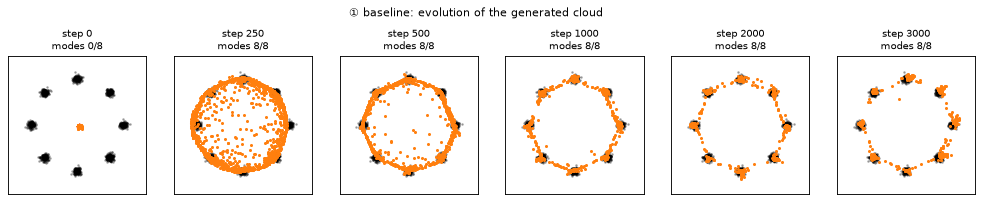

HTML(value='<b>① final state</b>')

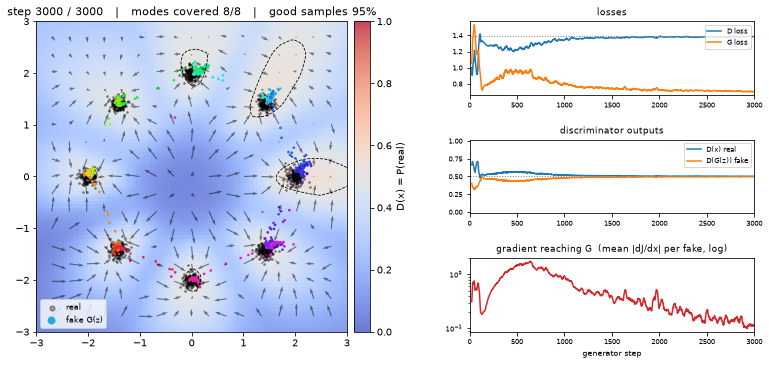

In [10]:
# ① Baseline
fr, sn, hi = toy_results["1"] = run_preset(P[0])
show_snaps(sn, "8 Gaussians (ring)", [0, 1, 2, 4, 8, len(sn) - 1], "① baseline: evolution of the generated cloud")
show_png(fr[-1], "① final state")

② Equilibrium: a single Gaussian (watch D → 0.5)  -> 25s | final D(x)=0.50  D(G(z))=0.50  D loss=1.388 | grad to G: first 100 steps 2.78e-01, last 100 8.53e-02


HTML(value='<b>② final state</b>')

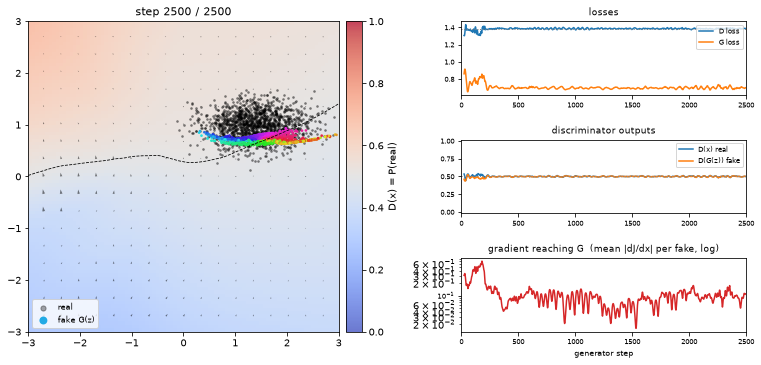

In [11]:
# ② Equilibrium
fr, sn, hi = toy_results["2"] = run_preset(P[1])
show_png(fr[-1], "② final state")

③ Saturating minimax loss: D gets a head start, G uses plain SGD  -> 13s | final D(x)=0.50  D(G(z))=0.50  D loss=1.386 | grad to G: first 100 steps 2.77e-03, last 100 4.72e-02


HTML(value='<b>③ minimax + SGD, step 500</b>')

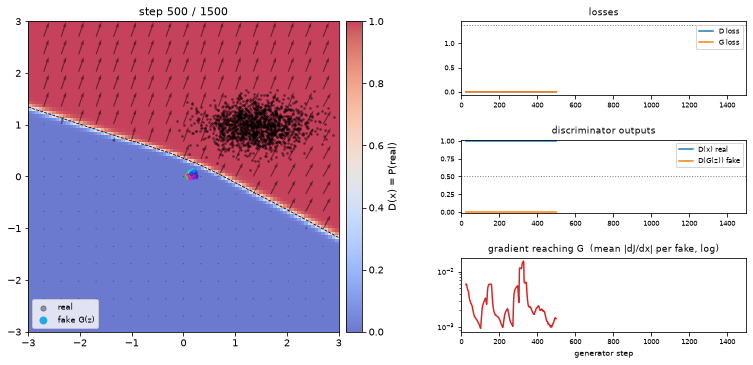

HTML(value='<b>③ minimax + SGD, final state</b>')

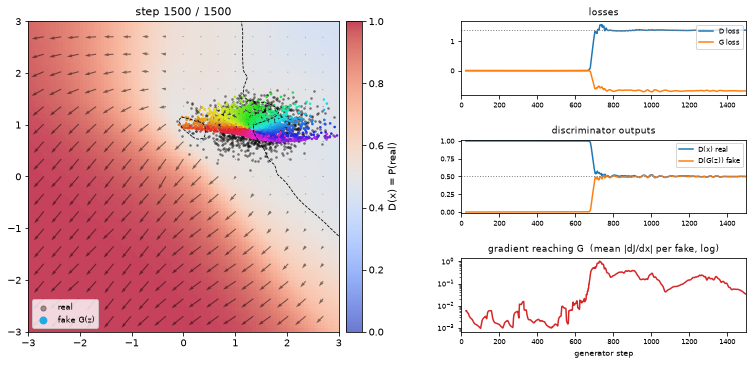

③ Saturating minimax loss: D gets a head start, G uses plain SGD {'loss': 'non-saturating'} -> 13s | final D(x)=0.50  D(G(z))=0.50  D loss=1.390 | grad to G: first 100 steps 8.09e-01, last 100 2.47e-01


HTML(value='<b>③ with the NON-SATURATING loss, final state</b>')

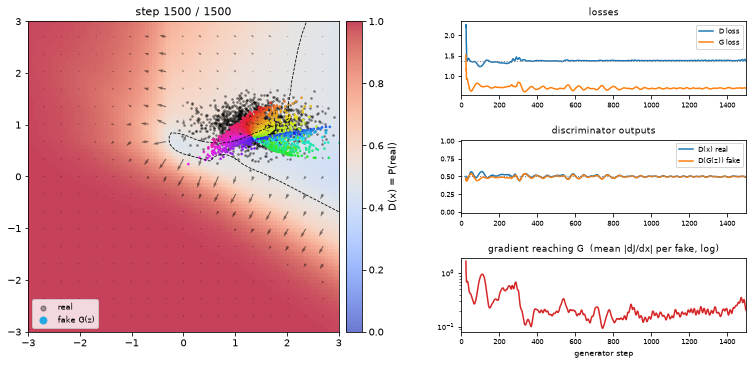

③ Saturating minimax loss: D gets a head start, G uses plain SGD {'g_optimizer': 'Adam', 'lr_g': 0.001} -> 15s | final D(x)=0.50  D(G(z))=0.50  D loss=1.385 | grad to G: first 100 steps 3.87e-01, last 100 4.00e-02


HTML(value='<b>③ bonus: minimax loss with Adam (lr G = 1e-3), final state</b>')

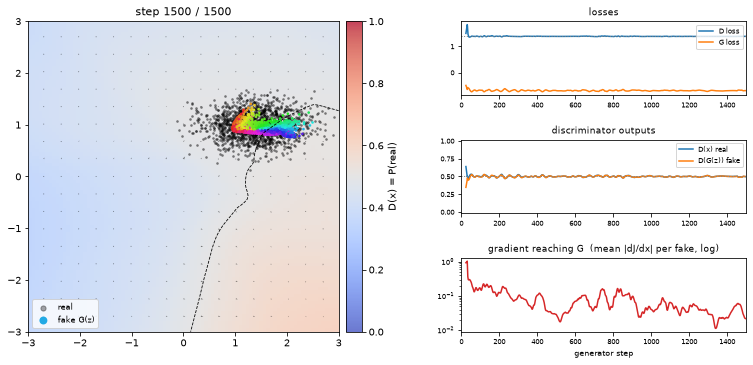

In [12]:
# ③ Saturating minimax loss with SGD, then the same with the non-saturating loss, then minimax + Adam (bonus)
fr, sn, hi = toy_results["3"] = run_preset(P[2])
show_png(fr[2], "③ minimax + SGD, step 500")
show_png(fr[-1], "③ minimax + SGD, final state")
fr, sn, hi = toy_results["3ns"] = run_preset(P[2], loss="non-saturating")
show_png(fr[-1], "③ with the NON-SATURATING loss, final state")
fr, sn, hi = toy_results["3adam"] = run_preset(P[2], g_optimizer="Adam", lr_g=1e-3)
show_png(fr[-1], "③ bonus: minimax loss with Adam (lr G = 1e-3), final state")

④ Mode collapse: generator 10× faster than discriminator  -> 49s | final D(x)=0.49  D(G(z))=0.49  D loss=1.387 | modes covered 0/8, good samples 0% | grad to G: first 100 steps 4.34e-02, last 100 4.89e-02


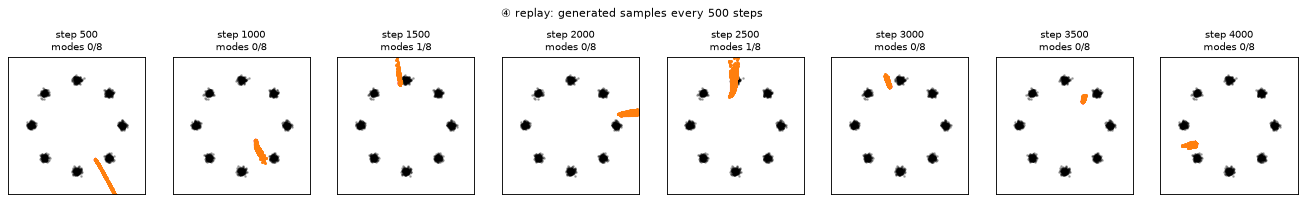

HTML(value='<b>④ final state (seed 0)</b>')

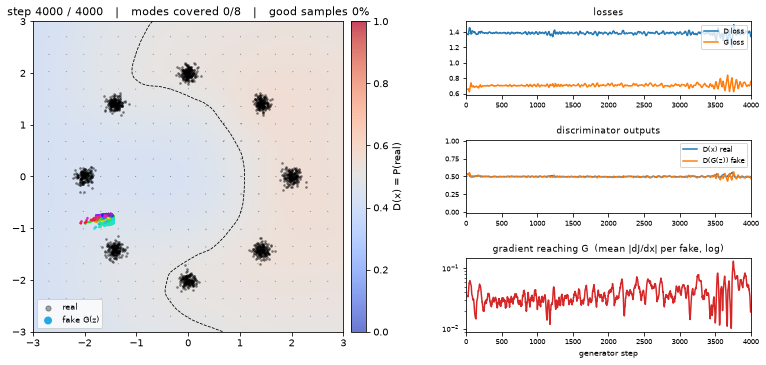

④ Mode collapse: generator 10× faster than discriminator {'seed': 1} -> 41s | final D(x)=0.50  D(G(z))=0.50  D loss=1.389 | modes covered 1/8, good samples 87% | grad to G: first 100 steps 4.09e-02, last 100 2.85e-02


④ Mode collapse: generator 10× faster than discriminator {'seed': 2} -> 47s | final D(x)=0.49  D(G(z))=0.50  D loss=1.393 | modes covered 0/8, good samples 1% | grad to G: first 100 steps 4.92e-02, last 100 3.82e-02


④ Mode collapse: generator 10× faster than discriminator {'seed': 3} -> 46s | final D(x)=0.50  D(G(z))=0.50  D loss=1.385 | modes covered 0/8, good samples 0% | grad to G: first 100 steps 4.63e-02, last 100 3.68e-02


④ Mode collapse: generator 10× faster than discriminator {'lr_d': 0.001} -> 44s | final D(x)=0.50  D(G(z))=0.50  D loss=1.386 | modes covered 8/8, good samples 98% | grad to G: first 100 steps 5.33e-01, last 100 7.77e-02


HTML(value='<b>④ with equal learning rates (lr D = 1e-3), final state</b>')

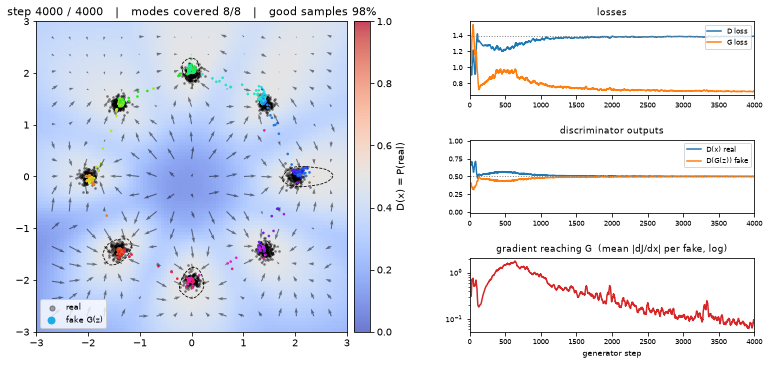

In [13]:
# ④ Mode collapse (G 10x faster than D): seed 0, replay, other seeds, equal learning rates
fr, sn, hi = toy_results["4"] = run_preset(P[3], snap_every=100)
show_snaps(sn, "8 Gaussians (ring)", list(range(5, len(sn), 5)), "④ replay: generated samples every 500 steps")
show_png(fr[-1], "④ final state (seed 0)")
for seed in (1, 2, 3):
    run_preset(P[3], seed=seed)
fr, sn, hi = toy_results["4eq"] = run_preset(P[3], lr_d=1e-3)
show_png(fr[-1], "④ with equal learning rates (lr D = 1e-3), final state")

⑤ WGAN-GP with the same learning rates as ④  -> 106s | final W estimate=0.042 | modes covered 8/8, good samples 94% | grad to G: first 100 steps 1.12e+00, last 100 9.02e-01


HTML(value='<b>⑤ WGAN-GP, final state</b>')

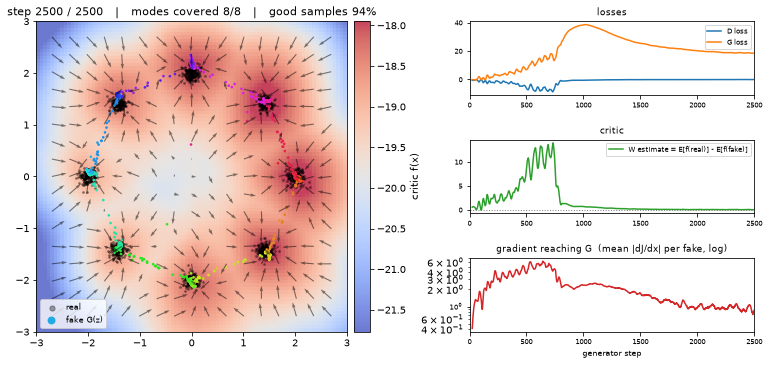

④ Mode collapse: generator 10× faster than discriminator {'d_steps': 5, 'steps': 2500} -> 62s | final D(x)=0.51  D(G(z))=0.49  D loss=1.370 | modes covered 8/8, good samples 97% | grad to G: first 100 steps 2.82e-01, last 100 3.06e-01


HTML(value='<b>④ (non-saturating GAN) with 5 D steps per G step, final state</b>')

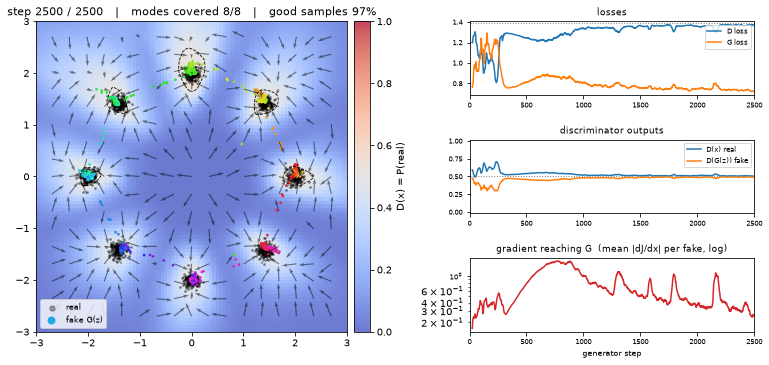

In [14]:
# ⑤ WGAN-GP with the same learning rates as ④, and ④ with 5 D steps per G step
fr, sn, hi = toy_results["5"] = run_preset(P[4])
show_png(fr[-1], "⑤ WGAN-GP, final state")
fr, sn, hi = toy_results["4d5"] = run_preset(P[3], d_steps=5, steps=2500)
show_png(fr[-1], "④ (non-saturating GAN) with 5 D steps per G step, final state")

⑥ Free play: two moons {'dataset': '25 Gaussians (grid)', 'nz': 8, 'steps': 5000} -> 50s | final D(x)=0.65  D(G(z))=0.35  D loss=1.036 | modes covered 15/25, good samples 83% | grad to G: first 100 steps 5.79e-01, last 100 2.40e+00


HTML(value='<b>⑥ 25-Gaussian grid, latent dim 8, lr G = lr D = 1e-3</b>')

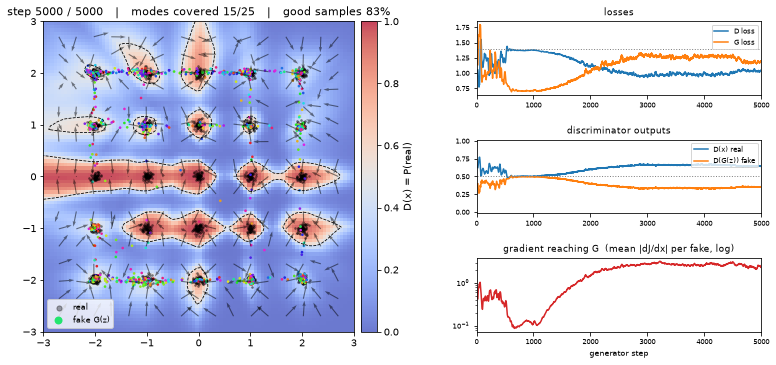

⑥ Free play: two moons {'dataset': '25 Gaussians (grid)', 'nz': 2, 'lr_g': 0.01, 'lr_d': 0.0001, 'steps': 5000} -> 55s | final D(x)=0.89  D(G(z))=0.13  D loss=0.367 | modes covered 0/25, good samples 0% | grad to G: first 100 steps 1.22e-02, last 100 1.59e+00


HTML(value='<b>⑥ 25-Gaussian grid, latent dim 2, lr G = 1e-2, lr D = 1e-4</b>')

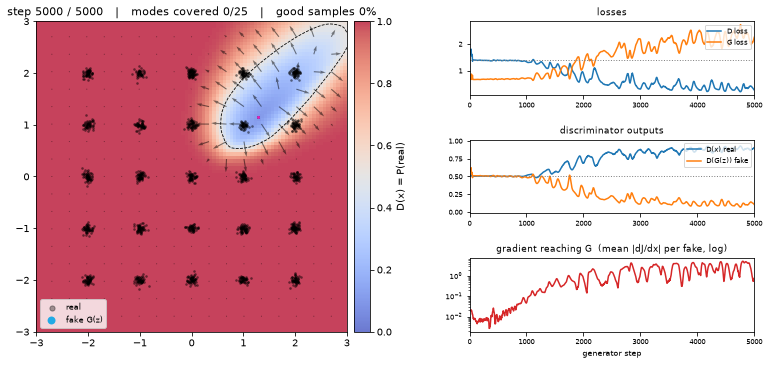

⑥ Free play: two moons {'dataset': 'spiral', 'nz': 8, 'steps': 5000} -> 54s | final D(x)=0.50  D(G(z))=0.50  D loss=1.389 | grad to G: first 100 steps 1.15e+00, last 100 1.92e-01


HTML(value='<b>⑥ spiral, latent dim 8</b>')

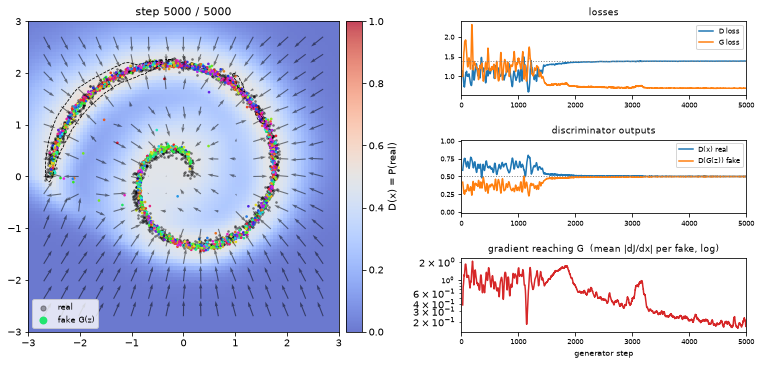

In [15]:
# ⑥ Free play: one setting that trains well and one that fails
fr, sn, hi = toy_results["6good"] = run_preset(P[5], dataset="25 Gaussians (grid)", nz=8, steps=5000)
show_png(fr[-1], "⑥ 25-Gaussian grid, latent dim 8, lr G = lr D = 1e-3")
fr, sn, hi = toy_results["6bad"] = run_preset(P[5], dataset="25 Gaussians (grid)", nz=2, lr_g=1e-2, lr_d=1e-4, steps=5000)
show_png(fr[-1], "⑥ 25-Gaussian grid, latent dim 2, lr G = 1e-2, lr D = 1e-4")
fr, sn, hi = toy_results["6spiral"] = run_preset(P[5], dataset="spiral", nz=8, steps=5000)
show_png(fr[-1], "⑥ spiral, latent dim 8")

#### Answers (Part 1)

1. **① Baseline.** At step 0 all fakes sit in a small blob at the origin. The arrows point *outwards*, towards the real data, so the cloud first expands into a disk (step 250), then concentrates on a ring (step 500) and finally splits into the 8 clusters (8/8 modes, 95 % good samples). The arrows point towards the closest red (= "real" for $D$) region. When a fake point lands on a real mode, $D$ can no longer tell it apart, $D(x)\approx 0.5$ there and the arrows around it become short: the point stays. Because $G$ is continuous and $z$ is a single connected Gaussian blob, $G$ cannot cut it into 8 pieces. Neighbouring colours (neighbouring $z$ directions) are mapped to neighbouring modes, and the $z$'s in between produce **trails of points between the clusters** (the "bridges" of colour-gradient points in the final plot). Those are the samples that are not "good".
2. **② Equilibrium.** Both $D(x)$ and $D(G(z))$ reach **0.50**. The background becomes almost uniformly **white/grey ($D\approx 0.5$)** around the data, because when $p_g = p_{data}$ the optimal discriminator is $D^*(x) = p_{data}/(p_{data}+p_g) = 1/2$ everywhere: it can only guess. The D loss approaches $2\log 2 \approx 1.386$ (we measured 1.388): $-\log(0.5) - \log(1-0.5) = 2\log 2$, i.e. the value of the BCE of a classifier that always outputs 0.5.
3. **③ Saturating loss.** After the 500-step head start $D$ rejects the fakes with total confidence ($D(G(z))\approx 0$, deep blue region). The arrows are **long only near the decision boundary** and **almost zero (dots) in the blue region where the fakes are**: exactly where $G$ needs them. With plain SGD, the gradient reaching $G$ is $\approx 3\cdot10^{-3}$ during the first 100 steps and $G$ stays stuck at the origin for **≈650-700 generator steps**. Only after that the fakes reach the data and the game converges ($D \to 0.5$). With the **non-saturating** loss and everything else the same, the gradient reaching $G$ is ≈0.8 from the very first step (≈300× larger) and $G$ starts moving immediately. This is exactly the plot in 1.1: for $D(G(z))\to 0$ the minimax loss $\log(1-D)$ is flat (gradient $= D(G(z)) \approx 0$), while $-\log D$ is steep (gradient $= 1 - D(G(z)) \approx 1$).
   *Bonus:* with the minimax loss and **Adam** (lr G = 1e-3) $G$ also escapes quickly (gradient ≈0.39 after the first steps). Adam divides each update by a running estimate of the gradient magnitude, $\Delta\theta \approx -\text{lr}\cdot \hat m/\sqrt{\hat v}$, so even a tiny but consistent gradient produces steps of size ≈lr. Adam therefore **hides** the vanishing gradient: training "works", but the information that the signal was almost zero is lost, and the gradient direction becomes noise-dominated when it is that small.
4. **④ Mode collapse.** With seed 0, **0/8 modes** are covered at the end (0 % good samples). The replay shows that $G$ squeezes all samples into a thin streak that **jumps from place to place**: near the bottom mode at step 500, then between modes, near the top mode at step 1500, to the right at 2000, top again at 2500... It never settles. $D$ does not stop it because it learns 10× slower: by the time $D$ has learned that the current location is "fake", $G$ has already jumped to a new spot that $D$ still considers real, and $D$ has *forgotten* the previous one. Each $G$ step only optimises against the current $D$, so the best response is always to move the whole cloud to the current most "real-looking" spot. Remarkably, the final $D(x)$ and $D(G(z))$ are both ≈0.5 and the D loss is ≈1.386, the *same* values as in the perfect equilibrium of ②: the losses do not reveal the collapse. Other seeds: seed 1 → 1/8 modes (all samples on one mode, 87 % "good"), seed 2 → 0/8, seed 3 → 0/8. With **equal learning rates** (lr D = 1e-3) the same setting covers **8/8 modes with 98 % good samples**.
5. **⑤ WGAN-GP** (same learning rates as ④): **8/8 modes, 94 % good samples**. The critic's surface is very different: instead of saturating to 0/1 with flat regions, it is a smooth landscape with a peak on each mode and arrows of similar length everywhere, all pointing to the nearest mode. The gradient reaching $G$ never vanishes (≈1 throughout). The **W estimate** curve rises while $D$ learns to separate the distributions and then decreases steadily towards ≈0.04 as the fakes cover all the modes: unlike the GAN losses, it *correlates with sample quality*. However, running ④ (non-saturating GAN) with **5 D steps per G step** also gives **8/8 modes and 97 % good samples**. So in this toy problem most of the improvement comes from **re-balancing the game** (the discriminator/critic gets 5 updates and keeps up with $G$), not only from the Wasserstein loss. The real advantages of WGAN-GP are the non-saturating, informative gradient everywhere and the meaningful W estimate.
6. **Free play.**
   - *Trains reasonably well:* 25-Gaussian grid with **latent dim 8** and equal learning rates: 15/25 modes clearly covered and 83 % of good samples, with points on (almost) every mode but a few modes under-populated and some trails between them. Also the **spiral** with latent dim 8: the samples follow the outer and middle arms of the spiral closely ($D\to0.5$), although the innermost part of the spiral is missing.
   - *Fails:* 25-Gaussian grid, latent dim 2, **lr G = 1e-2, lr D = 1e-4**: 0/25 modes, 0 % good samples. The generator is 100× faster than the discriminator, so it collapses and runs away (the fakes end up outside the plotted region) while $D$ ends up confidently classifying everything as real (all red). Moreover, a 2-D latent space mapped continuously onto 25 disconnected modes necessarily creates many trails between them; a higher latent dimension gives $G$ more freedom to "tear" the space between modes.

### 1.3 Why Wasserstein? JS divergence vs Earth-Mover distance

The original GAN (with an optimal discriminator) minimises the Jensen–Shannon divergence. When the real and generated distributions **don't overlap** (very common for images, which live on thin manifolds in pixel space), JSD is stuck at $\log 2$ **no matter how far apart they are**, so it gives no useful gradient. The Wasserstein-1 (Earth-Mover) distance grows smoothly with the distance (slides: *Wasserstein GANs, Arjovsky 2017*).

Move the generated distribution $p_g$ (orange) towards the real one $p_{data}$ (black).

In [16]:
xs = np.linspace(-6, 6, 2401); dx = xs[1] - xs[0]
def bump(c, w=0.6):
    p = np.clip(1 - np.abs(xs - c) / w, 0, None)
    return p / (p.sum() * dx)
def jsd(p, q):
    m = 0.5 * (p + q)
    kl = lambda a, b: np.sum(np.where(a > 0, a * np.log(np.where(a > 0, a, 1) / np.where(b > 0, b, 1)), 0)) * dx
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)
def w1(p, q):
    return np.sum(np.abs(np.cumsum(p) - np.cumsum(q))) * dx * dx

p_data = bump(0.0)
thetas = np.linspace(-4, 4, 161)
JS = np.array([jsd(p_data, bump(t)) for t in thetas]); W = np.array([w1(p_data, bump(t)) for t in thetas])

js_img = widgets.Image(format="png")
theta = widgets.FloatSlider(value=3.0, min=-4, max=4, step=0.05, description="shift θ", layout=widgets.Layout(width="500px"))
def draw_js():
    t = theta.value; q = bump(t)
    fig = Figure(figsize=(12, 3.4)); a1, a2 = fig.subplots(1, 2)
    a1.fill_between(xs, p_data, color="k", alpha=0.3, label="$p_{data}$"); a1.fill_between(xs, q, color="C1", alpha=0.5, label=r"$p_g$ (shifted by θ)")
    a1.set_xlim(-5, 5); a1.legend(); a1.set_yticks([]); a1.set_title("The two distributions")
    a2.plot(thetas, JS, lw=2.5, label="JS divergence"); a2.plot(thetas, W, lw=2.5, label="Wasserstein-1 distance")
    a2.axhline(np.log(2), color="C0", ls=":", lw=1); a2.text(-3.9, np.log(2) + 0.08, "log 2", color="C0")
    a2.plot([t], [jsd(p_data, q)], "o", color="C0", ms=9); a2.plot([t], [w1(p_data, q)], "o", color="C1", ms=9)
    a2.set_xlabel("θ"); a2.legend(loc="upper center"); a2.set_title("Distance between them as a function of θ")
    js_img.value = fig_to_png(fig)
on_change(draw_js, theta)
display(widgets.VBox([theta, js_img]))

> 🔎 **Question.** For which values of θ is the JS divergence *flat*? What does that mean for a generator trained by following the gradient of JSD? Why is the Wasserstein distance better behaved, and what is the price WGAN pays to estimate it (hint: 1-Lipschitz critic, weight clipping vs gradient penalty)?

HTML(value='<b>θ = 3.0</b>')

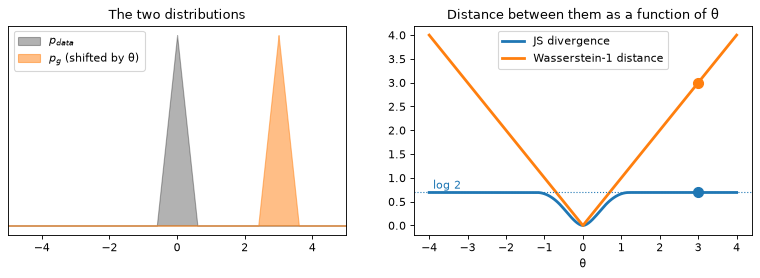

HTML(value='<b>θ = 0.3</b>')

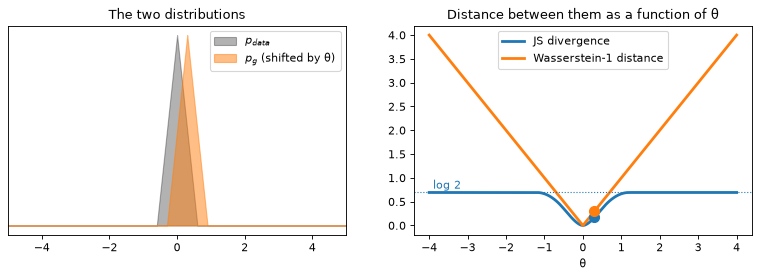

θ = -3.0:  JSD = 0.693   (log 2 = 0.693)   W1 = 3.000
θ = -1.5:  JSD = 0.693   (log 2 = 0.693)   W1 = 1.500
θ = -0.8:  JSD = 0.582   (log 2 = 0.693)   W1 = 0.800
θ = -0.3:  JSD = 0.169   (log 2 = 0.693)   W1 = 0.300
θ = +0.0:  JSD = 0.000   (log 2 = 0.693)   W1 = 0.000
θ = +0.3:  JSD = 0.169   (log 2 = 0.693)   W1 = 0.300
θ = +0.8:  JSD = 0.582   (log 2 = 0.693)   W1 = 0.800
θ = +1.5:  JSD = 0.693   (log 2 = 0.693)   W1 = 1.500
θ = +3.0:  JSD = 0.693   (log 2 = 0.693)   W1 = 3.000


In [17]:
for t in (3.0, 0.3):
    theta.value = t
    show_png(js_img.value, f"θ = {t}")
for t in (-3, -1.5, -0.8, -0.3, 0, 0.3, 0.8, 1.5, 3):
    print(f"θ = {t:+.1f}:  JSD = {jsd(p_data, bump(t)):.3f}   (log 2 = {np.log(2):.3f})   W1 = {w1(p_data, bump(t)):.3f}")

**Answer.** For this example (two triangular bumps of half-width 0.6) the JS divergence is **flat, exactly equal to $\log 2 \approx 0.693$, for every $|\theta| \geq 1.2$**, i.e. whenever the two distributions don't overlap (see the printed values: $\theta = \pm1.5, \pm3$ all give 0.693). It only varies when they overlap ($|\theta| < 1.2$). For a generator trained by following the gradient of JSD this means **zero gradient**: from $\theta = 3$ it has no information about in which direction to move $p_g$, so it doesn't learn. This is the situation of real images, which lie on thin manifolds that almost never overlap at the beginning of training. The **Wasserstein-1 distance is $|\theta|$** here: it grows linearly with the distance between the distributions and its gradient always points towards $p_{data}$, even without overlap. The price: WGAN estimates $W_1$ through the Kantorovich-Rubinstein duality, $W_1 = \sup_{\|f\|_L\le 1} \mathbb{E}_{p_{data}}[f] - \mathbb{E}_{p_g}[f]$, so the critic must be **1-Lipschitz**. Weight clipping enforces it crudely (it limits the capacity of the critic and can cause vanishing/exploding gradients, depending on the clipping value). The gradient penalty (WGAN-GP) instead penalises $(\|\nabla_x f(\hat x)\|-1)^2$ on interpolated points, which works better but costs an extra backward pass (a second-order gradient), and the critic usually needs several updates per generator step (5 here), so training is slower.

---
## 2. DCGAN on MNIST

Now the real thing: a **Deep Convolutional GAN** (slides: *DCGAN Architecture, Radford 2015*) that generates $28\times28$ handwritten digits. The DCGAN recipe:

- No pooling: **strided convolutions** in $D$ (downsampling) and **transposed convolutions** in $G$ (upsampling), so the networks learn their own resampling.
- **Batch normalisation** in both networks (except $G$'s output and $D$'s input layers).
- **ReLU** in $G$ with **tanh** at the output (images are scaled to $[-1, 1]$); **LeakyReLU(0.2)** in $D$.
- Adam with learning rate $2\cdot10^{-4}$ and $\beta_1 = 0.5$; weights initialised from $\mathcal{N}(0, 0.02)$.

First, the data. We load all of MNIST into memory once (it's small) and scale pixels to $[-1,1]$ to match the generator's tanh output.

In [18]:
mnist_train = torchvision.datasets.MNIST(DATA_DIR, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(DATA_DIR, train=False, download=True)
to_tensor = lambda ds: (ds.data.float().div(255).sub(0.5).div(0.5).unsqueeze(1), ds.targets.clone())
X_train, Y_train = to_tensor(mnist_train)
X_test, Y_test = to_tensor(mnist_test)
X_train, Y_train = X_train.to(device), Y_train.to(device)
print("train:", tuple(X_train.shape), " pixel range:", X_train.min().item(), "to", X_train.max().item())

mnist_preview = widgets.Image(value=tensor_grid_png(X_train[:64], nrow=16, scale=2), format="png")
display(widgets.VBox([widgets.HTML("<b>Some real training images</b>"), mnist_preview]))

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  1%|          | 65.5k/9.91M [00:00<00:32, 306kB/s]

  2%|▏         | 164k/9.91M [00:00<00:17, 555kB/s] 

  3%|▎         | 295k/9.91M [00:00<00:12, 788kB/s]

  4%|▍         | 426k/9.91M [00:00<00:10, 925kB/s]

  7%|▋         | 688k/9.91M [00:00<00:06, 1.41MB/s]

... (15 outputs left out)

100%|██████████| 1.65M/1.65M [00:00<00:00, 2.12MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 1.90MB/s]

train: (60000, 1, 28, 28)  pixel range: -1.0 to 1.0


### 2.1 The networks

The generator turns a latent vector $z \in \mathbb{R}^{100}$ into an image by repeatedly upsampling:
$z \to 256\times7\times7 \to 128\times14\times14 \to 1\times28\times28$.
The discriminator mirrors it: $1\times28\times28 \to 64\times14\times14 \to 128\times7\times7 \to$ one logit.

Both classes accept an optional label (`n_classes > 0`) which we will only use for the conditional GAN in Part 5.

In [19]:
NZ = 100

def weights_init(m):
    # DCGAN initialisation: conv weights ~ N(0, 0.02), batch-norm scale ~ N(1, 0.02), bias = 0
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

class Generator(nn.Module):
    def __init__(self, nz=NZ, ngf=64, n_classes=0):
        super().__init__()
        self.nz, self.n_classes = nz, n_classes
        self.blocks = nn.ModuleList([
            nn.Sequential(nn.ConvTranspose2d(nz + n_classes, ngf * 4, 7, 1, 0, bias=False),    # -> (256, 7, 7)
                          nn.BatchNorm2d(ngf * 4), nn.ReLU(True)),
            nn.Sequential(nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),           # -> (128, 14, 14)
                          nn.BatchNorm2d(ngf * 2), nn.ReLU(True)),
            nn.Sequential(nn.ConvTranspose2d(ngf * 2, 1, 4, 2, 1, bias=False), nn.Tanh()),     # -> (1, 28, 28) in [-1, 1]
        ])
    def forward(self, z, y=None, return_features=False):
        if self.n_classes:
            z = torch.cat([z, F.one_hot(y, self.n_classes).float()], 1)
        x = z.view(z.size(0), -1, 1, 1)               # a vector is a 1x1 "image" with nz channels
        features = []
        for block in self.blocks:
            x = block(x); features.append(x)
        return (x, features) if return_features else x

class Discriminator(nn.Module):
    def __init__(self, ndf=64, n_classes=0):
        super().__init__()
        self.n_classes = n_classes
        self.net = nn.Sequential(
            nn.Conv2d(1 + n_classes, ndf, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),          # -> (64, 14, 14)
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False), nn.BatchNorm2d(ndf * 2), nn.LeakyReLU(0.2, True),  # -> (128, 7, 7)
            nn.Conv2d(ndf * 2, 1, 7, 1, 0, bias=False))                                         # -> (1, 1, 1): a logit
    def forward(self, x, y=None):
        if self.n_classes:                            # conditional: the label is appended as constant image channels
            maps = F.one_hot(y, self.n_classes).float()[:, :, None, None].expand(-1, -1, x.size(2), x.size(3))
            x = torch.cat([x, maps], 1)
        return self.net(x).view(-1)

G = Generator().to(device); G.apply(weights_init)
D = Discriminator().to(device); D.apply(weights_init)
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(G); print(D)
print(f"\nG: {n_params(G):,} parameters   D: {n_params(D):,} parameters")
with torch.no_grad():
    z = torch.randn(2, NZ, device=device)
    img, feats = G(z, return_features=True)
    print("shapes through G:", [tuple(f.shape[1:]) for f in feats], "   D output:", tuple(D(img).shape))

Generator(
  (blocks): ModuleList(
    (0): Sequential(
      (0): ConvTranspose2d(100, 256, kernel_size=(7, 7), stride=(1, 1), bias=False)
      (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): Sequential(
      (0): ConvTranspose2d(128, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
      (1): Tanh()
    )
  )
)
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1

shapes through G: [(256, 7, 7), (128, 14, 14), (1, 28, 28)]    D output: (2,)


### 2.2 Training with a live dashboard

Each iteration follows Algorithm 1 of Goodfellow et al. (with $k=1$), using **binary cross-entropy** for both players:

1. **Update $D$:** maximise $\log D(x) + \log(1 - D(G(z)))$. Real batch with label 1, fake batch with label 0 (separate mini-batches, as recommended by *ganhacks*). The fake images are `detach()`ed so this step doesn't touch $G$.
2. **Update $G$:** the **non-saturating** loss: maximise $\log D(G(z))$, implemented as BCE with label **1** ("real") on the fake images. Only $G$'s optimiser takes a step.

The dashboard shows the generator's output for a **fixed** set of 64 latent vectors, so you can watch the *same* $z$'s turn into digits. The trained model is saved in `gan_lab_outputs/`; if a checkpoint exists, the cell loads it instead of retraining (set `RETRAIN = True` to force training).

In [20]:
def train_gan_mnist(G, D, epochs=5, lr=2e-4, beta1=0.5, batch_size=128, conditional=False, real_label=1.0, lr_d=None,
                    frame_every=50, title="DCGAN"):
    bce = nn.BCEWithLogitsLoss()                      # = sigmoid + BCE, numerically safer
    optD = torch.optim.Adam(D.parameters(), lr=lr if lr_d is None else lr_d, betas=(beta1, 0.999))   # lr_d: optional separate D learning rate
    optG = torch.optim.Adam(G.parameters(), lr=lr, betas=(beta1, 0.999))
    gen = torch.Generator().manual_seed(1234)
    if conditional:                                   # fixed grid: one row per z, one column per digit
        fixed_z = torch.randn(10, G.nz, generator=gen).repeat_interleave(10, 0).to(device)
        fixed_y = torch.arange(10).repeat(10).to(device); nrow = 10
    else:
        fixed_z = torch.randn(64, G.nz, generator=gen).to(device); fixed_y = None; nrow = 8
    hist = {k: [] for k in ["d_loss", "g_loss", "d_real", "d_fake"]}
    frames = []
    n = X_train.size(0); iters_per_epoch = n // batch_size; total = epochs * iters_per_epoch
    ones = torch.ones(batch_size, device=device); zeros = torch.zeros(batch_size, device=device)
    real_targets = torch.full((batch_size,), real_label, device=device)   # real_label < 1: "one-sided label smoothing"

    dash, status = widgets.Image(format="png"), widgets.HTML()
    display(widgets.VBox([status, dash]))

    def make_frame(it, epoch):
        G.eval()
        with torch.no_grad():
            samples = G(fixed_z, fixed_y)
        G.train()
        grid = vutils.make_grid(samples.cpu(), nrow=nrow, padding=2, normalize=True, value_range=(-1, 1), pad_value=1)
        fig = Figure(figsize=(13, 4.6))
        gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.5], hspace=0.45, wspace=0.15)
        a0 = fig.add_subplot(gs[:, 0]); a0.imshow(grid[0], cmap="gray"); a0.axis("off")
        a0.set_title(f"{title}: G(fixed z) at iteration {it} (epoch {epoch})", fontsize=10)
        a1 = fig.add_subplot(gs[0, 1]); a2 = fig.add_subplot(gs[1, 1])
        if hist["d_loss"]:
            a1.plot(hist["d_loss"], color="C0", alpha=0.2); a1.plot(hist["g_loss"], color="C1", alpha=0.2)
            a1.plot(*smooth(hist["d_loss"]), color="C0", label="D loss"); a1.plot(*smooth(hist["g_loss"]), color="C1", label="G loss")
            a2.plot(*smooth(hist["d_real"]), color="C2", label="D(x) on real"); a2.plot(*smooth(hist["d_fake"]), color="C3", label="D(G(z)) on fake")
            a1.legend(fontsize=8, loc="upper right"); a2.legend(fontsize=8, loc="upper right")
        a2.axhline(0.5, color="gray", ls=":", lw=1); a2.set_ylim(0, 1)
        for a in (a1, a2):
            a.set_xlim(0, total); a.tick_params(labelsize=8)
        for e in range(1, epochs):
            a1.axvline(e * iters_per_epoch, color="gray", lw=0.5); a2.axvline(e * iters_per_epoch, color="gray", lw=0.5)
        a1.set_title("losses", fontsize=9); a2.set_title("discriminator outputs", fontsize=9); a2.set_xlabel("iteration", fontsize=8)
        png = fig_to_png(fig, dpi=72)
        frames.append(png); dash.value = png

    t0, it = time.time(), 0
    G.train(); D.train()
    make_frame(0, 0)
    for epoch in range(1, epochs + 1):
        perm = torch.randperm(n, device=X_train.device)
        for i in range(iters_per_epoch):
            idx = perm[i * batch_size:(i + 1) * batch_size]
            real, y_real = X_train[idx], Y_train[idx]
            z = torch.randn(batch_size, G.nz, device=device)
            y_fake = torch.randint(0, 10, (batch_size,), device=device) if conditional else None
            fake = G(z, y_fake)

            # (1) Discriminator: real -> 1, fake -> 0
            l_real = D(real, y_real if conditional else None)
            l_fake = D(fake.detach(), y_fake)
            lossD = bce(l_real, real_targets) + bce(l_fake, zeros)
            optD.zero_grad(); lossD.backward(); optD.step()

            # (2) Generator (non-saturating): make D call the fakes real
            lossG = bce(D(fake, y_fake), ones)
            optG.zero_grad(); lossG.backward(); optG.step()

            it += 1
            hist["d_loss"].append(lossD.item()); hist["g_loss"].append(lossG.item())
            hist["d_real"].append(torch.sigmoid(l_real).mean().item()); hist["d_fake"].append(torch.sigmoid(l_fake).mean().item())
            if it % frame_every == 0 or it == total:
                make_frame(it, epoch)
                el = time.time() - t0
                status.value = (f"<b>epoch {epoch}/{epochs}</b>, iteration {it}/{total}, "
                                f"{el:.0f}s elapsed, ~{el / it * (total - it):.0f}s left")
    status.value = f"<b>Finished</b> {epochs} epochs ({total} iterations) in {time.time() - t0:.0f}s."
    G.eval(); D.eval()
    return hist, frames

def save_ckpt(path, G, D, hist, frames):
    torch.save({"G": G.state_dict(), "D": D.state_dict(), "hist": hist, "frames": frames}, path)

def load_ckpt(path, G, D):
    ck = torch.load(path, map_location=device, weights_only=False)
    G.load_state_dict(ck["G"]); D.load_state_dict(ck["D"]); G.eval(); D.eval()
    return ck["hist"], ck["frames"]

In [21]:
EPOCHS = 5            # 5 epochs give clearly readable digits; 2-3 is enough if you are short of time
RETRAIN = False       # True: train again even if a saved model exists
CKPT = os.path.join(OUT_DIR, "dcgan_mnist.pt")

set_seed(0)
G = Generator().to(device); G.apply(weights_init)
D = Discriminator().to(device); D.apply(weights_init)
if os.path.exists(CKPT) and not RETRAIN:
    dcgan_hist, dcgan_frames = load_ckpt(CKPT, G, D)
    print(f"Loaded the trained DCGAN from {CKPT} (set RETRAIN = True to train again).")
else:
    dcgan_hist, dcgan_frames = train_gan_mnist(G, D, epochs=EPOCHS)
    save_ckpt(CKPT, G, D, dcgan_hist, dcgan_frames)

### 2.3 Replay the training

Scrub through the training: watch the fixed latent vectors go from noise, to blobs, to strokes, to digits.

In [22]:
def replay_widget(frames):
    img = widgets.Image(value=frames[-1], format="png")
    sl = widgets.IntSlider(value=len(frames) - 1, min=0, max=len(frames) - 1, description="frame", layout=widgets.Layout(width="600px"))
    play = widgets.Play(value=len(frames) - 1, min=0, max=len(frames) - 1, interval=200)
    widgets.jslink((play, "value"), (sl, "value"))
    sl.observe(lambda ch: setattr(img, "value", frames[ch["new"]]), names="value")
    return widgets.VBox([widgets.HBox([play, sl]), img])

display(replay_widget(dcgan_frames))

> 🔎 **Questions (Part 2).**
> 1. In what order does the generator learn things (background, overall shape, strokes, digit identity)?
> 2. The losses don't go to zero and don't steadily decrease, unlike in supervised learning. Why not? What do the $D(x)$ and $D(G(z))$ curves tell you about who is "winning"? Do they approach the 0.5 equilibrium of Part 1?
> 3. Do the losses tell you *when* the images are good? Compare with the WGAN *W estimate* from Part 1.

HTML(value='<b>frame 0 of 47</b>')

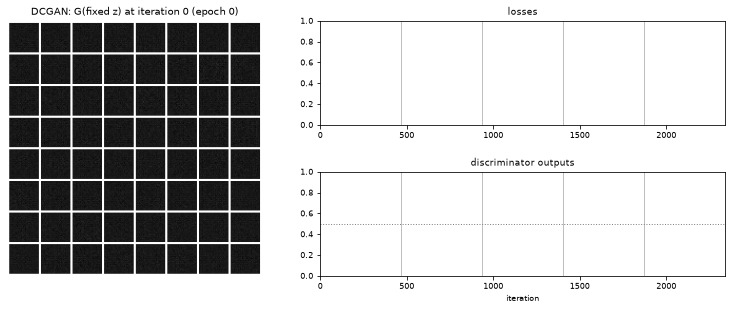

HTML(value='<b>frame 1 of 47</b>')

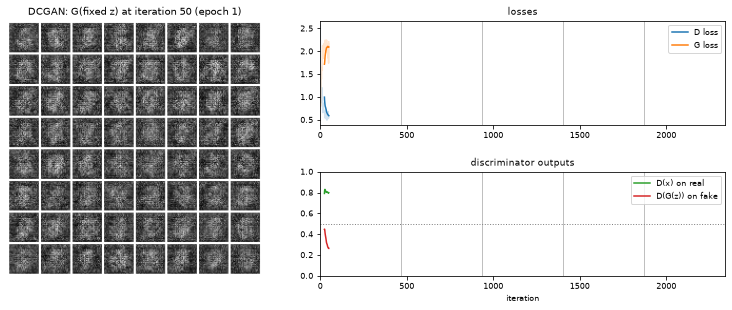

HTML(value='<b>frame 2 of 47</b>')

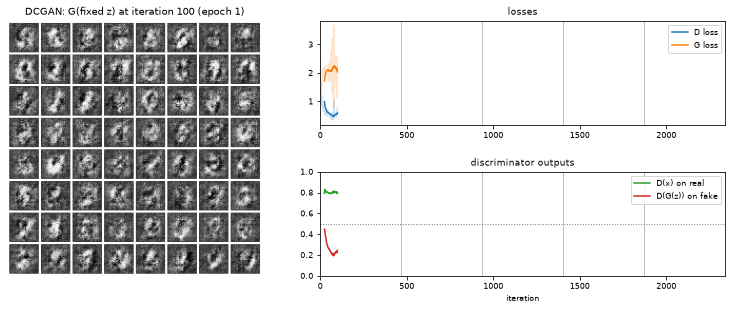

HTML(value='<b>frame 4 of 47</b>')

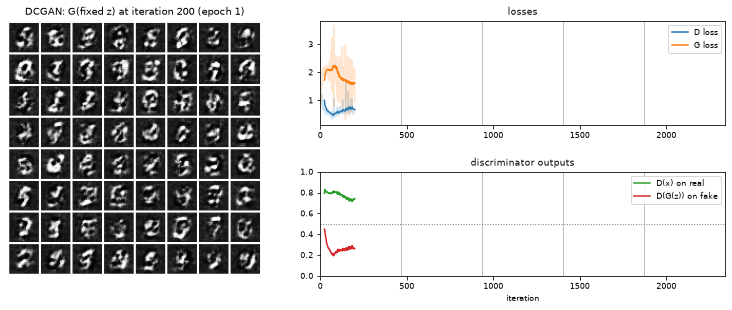

HTML(value='<b>frame 8 of 47</b>')

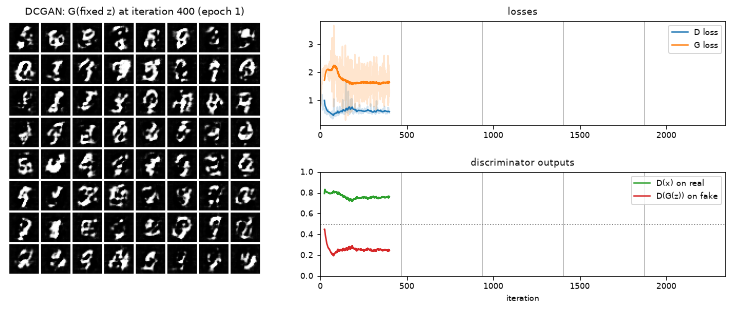

HTML(value='<b>frame 24 of 47</b>')

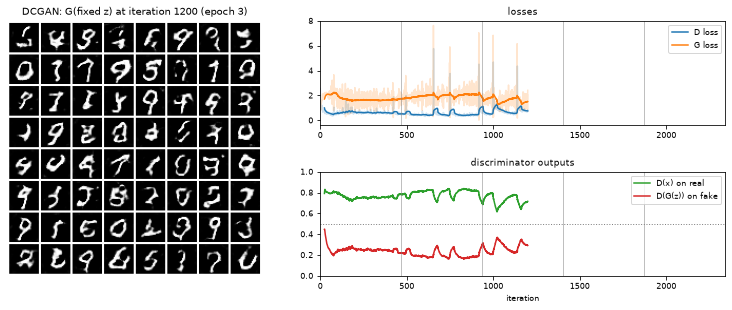

HTML(value='<b>frame 47 of 47</b>')

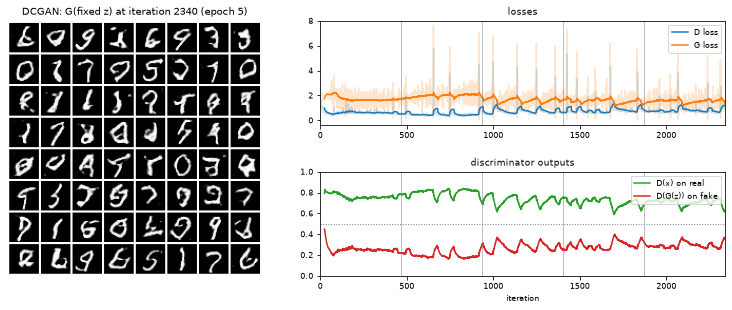

epoch 1: D loss 0.635  G loss 1.729  D(x) 0.763  D(G(z)) 0.257
epoch 2: D loss 0.544  G loss 1.966  D(x) 0.795  D(G(z)) 0.205
epoch 3: D loss 0.754  G loss 1.625  D(x) 0.725  D(G(z)) 0.274
epoch 4: D loss 0.836  G loss 1.547  D(x) 0.704  D(G(z)) 0.296
epoch 5: D loss 0.814  G loss 1.542  D(x) 0.705  D(G(z)) 0.294


In [23]:
idx = [0, 1, 2, 4, 8, len(dcgan_frames) // 2, len(dcgan_frames) - 1]
for k in idx:
    show_png(dcgan_frames[k], f"frame {k} of {len(dcgan_frames) - 1}")
n_it = len(dcgan_hist["d_loss"]); q = n_it // 5
for e in range(5):
    sl = slice(e * q, (e + 1) * q)
    print(f"epoch {e + 1}: D loss {np.mean(dcgan_hist['d_loss'][sl]):.3f}  G loss {np.mean(dcgan_hist['g_loss'][sl]):.3f}  "
          f"D(x) {np.mean(dcgan_hist['d_real'][sl]):.3f}  D(G(z)) {np.mean(dcgan_hist['d_fake'][sl]):.3f}")

**Answers (Part 2).**

1. **Order.** At iteration 0 the output is uniform noise. After ~100 iterations the generator has learned the **background** (dark borders) and a blurry bright **blob in the centre** (the average digit). Then it learns the **overall shape** (blobs with the rough size and position of a digit), next **strokes** (thin, connected lines with the right thickness), and finally the **digit identity** (clearly readable 0-9) from the end of epoch 1 / epoch 2 on. The last epochs only refine details. Generic, low-frequency statistics come first and the fine, class-specific structure comes last.
2. The losses don't go to zero because this is not a minimisation of a fixed objective but a **two-player game**: every improvement of one player makes the other player's loss larger, so the losses **oscillate** around a balance point (here D loss ≈0.6-0.8 and G loss ≈1.5-2 during all the training, with spikes). Throughout the training $D(x) \approx 0.7$-$0.8$ and $D(G(z)) \approx 0.2$-$0.3$ (per epoch: 0.76/0.26, 0.80/0.21, 0.73/0.27, 0.70/0.30, 0.71/0.29). **The discriminator is winning** all the time, but not by much and less and less: the curves slowly move towards each other in epochs 3-5. They do **not** reach the 0.5 equilibrium of Part 1. A real image distribution is much harder to match exactly than a 2-D Gaussian, and a finite discriminator can always find some small difference.
3. **No.** The losses are almost the same in epochs 2-5, while the images go from barely readable to clean digits; in Part 1 (④) the losses even showed the "perfect" equilibrium values while the generator had collapsed. The GAN losses only measure the current balance between the two players, not the distance to the data distribution. The **WGAN W estimate** of Part 1, in contrast, decreased steadily as the samples got better, so it could be used to monitor training. For a standard GAN you have to look at samples or use external metrics (FID, a classifier as in Part 4...).

---
## 3. Exploring the trained generator

A GAN has no encoder: it never maps a real image to a $z$. But the generator is a smooth function of $z$, so we can learn a lot by **moving around the latent space** and watching what happens. In all the explorers below, a *seed* picks a latent vector $z \sim \mathcal{N}(0, I_{100})$ reproducibly.

### 3.1 What does the discriminator think?

Each generated image is shown with the trained discriminator's score $D(G(z))$, sorted from "most real" to "most fake". Switch to real images to compare.

In [24]:
def z_from_seed(seed, n=1):
    g = torch.Generator().manual_seed(int(seed))
    return torch.randn(n, NZ, generator=g).to(device)

@torch.no_grad()
def generate(z, y=None, net=None):
    net = net or G
    net.eval()
    return net(z, y)

gal_img = widgets.Image(format="png")
gal_src = widgets.ToggleButtons(options=["generated", "real"], description="images")
gal_btn = widgets.Button(description="New batch", icon="refresh")
gal_seed = widgets.IntText(value=0, layout=widgets.Layout(display="none"))   # counts clicks on "New batch"

@torch.no_grad()
def draw_gallery():
    set_seed(gal_seed.value)
    if gal_src.value == "generated":
        x = generate(torch.randn(32, NZ, device=device))
    else:
        x = X_train[torch.randint(0, X_train.size(0), (32,), device=X_train.device)]
    D.eval()
    s = torch.sigmoid(D(x)).cpu().numpy(); order = np.argsort(-s)
    x = x.cpu()
    fig = Figure(figsize=(12, 6.4)); axes = fig.subplots(4, 8)
    for ax, k in zip(axes.flat, order):
        ax.imshow(x[k, 0], cmap="gray", vmin=-1, vmax=1); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"D = {s[k]:.2f}", fontsize=9, color=plt.cm.coolwarm(s[k]))
    fig.suptitle(f"{gal_src.value} images, sorted by D(x) (mean {s.mean():.2f})", fontsize=11)
    gal_img.value = fig_to_png(fig)

gal_btn.on_click(lambda _: setattr(gal_seed, "value", gal_seed.value + 1))
on_change(draw_gallery, gal_src, gal_seed)
display(widgets.VBox([widgets.HBox([gal_src, gal_btn]), gal_img]))

### 3.2 Walking between two latent vectors

Interpolate between $z_A$ and $z_B$. **Linear** interpolation $z(t) = (1-t)z_A + t z_B$ passes close to the origin, where Gaussian samples almost never are (in 100 dimensions, $\|z\| \approx \sqrt{100} = 10$). **Spherical** interpolation (slerp) stays on the sphere where the training $z$'s live. Watch the norm and the image quality in the middle of the path.

In [25]:
def slerp(a, b, t):
    an, bn = a / a.norm(dim=-1, keepdim=True), b / b.norm(dim=-1, keepdim=True)
    omega = torch.acos((an * bn).sum(-1, keepdim=True).clamp(-1 + 1e-7, 1 - 1e-7))
    so = torch.sin(omega)
    return torch.sin((1 - t) * omega) / so * a + torch.sin(t * omega) / so * b

int_a = widgets.IntSlider(value=1, min=0, max=500, description="seed A", layout=widgets.Layout(width="400px"))
int_b = widgets.IntSlider(value=2, min=0, max=500, description="seed B", layout=widgets.Layout(width="400px"))
int_mode = widgets.ToggleButtons(options=["linear", "spherical (slerp)"], description="path")
int_img = widgets.Image(format="png")

@torch.no_grad()
def draw_interp():
    za, zb = z_from_seed(int_a.value), z_from_seed(int_b.value)
    ts = torch.linspace(0, 1, 11, device=device).view(-1, 1)
    zs = (1 - ts) * za + ts * zb if int_mode.value == "linear" else slerp(za.expand(11, -1), zb.expand(11, -1), ts)
    x = generate(zs); s = torch.sigmoid(D(x)).cpu().numpy()
    fig = Figure(figsize=(13, 2.9)); axes = fig.subplots(1, 11)
    for k, ax in enumerate(axes):
        ax.imshow(x[k, 0].cpu(), cmap="gray", vmin=-1, vmax=1); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"t={ts[k].item():.1f}", fontsize=9)
        ax.set_xlabel(f"|z|={zs[k].norm().item():.1f}\nD={s[k]:.2f}", fontsize=8)
    int_img.value = fig_to_png(fig)

on_change(draw_interp, int_a, int_b, int_mode)
display(widgets.VBox([widgets.HBox([int_a, int_b]), int_mode, int_img]))

### 3.3 Does a single latent dimension mean something?

Each row is a different random $z$; along each row we change **only one coordinate** $z_i$ from $-r$ to $+r$. If dimension $i$ encoded one clean factor (thickness, slant, digit identity...), every row would change in the same way. This relates to the *entangled latent space* problem that StyleGAN addresses (slides: *Style GAN*).

In [26]:
dim_i = widgets.IntSlider(value=0, min=0, max=NZ - 1, description="dimension i", layout=widgets.Layout(width="500px"))
dim_r = widgets.FloatSlider(value=4.0, min=0.5, max=10, step=0.5, description="range ±r")
dim_seed = widgets.IntSlider(value=0, min=0, max=100, description="seeds from")
dim_img = widgets.Image(format="png")

@torch.no_grad()
def draw_dims():
    rows, cols = 6, 9
    z = z_from_seed(dim_seed.value, rows).repeat_interleave(cols, 0)
    z[:, dim_i.value] = torch.linspace(-dim_r.value, dim_r.value, cols, device=device).repeat(rows)
    dim_img.value = tensor_grid_png(generate(z), nrow=cols, scale=3)

on_change(draw_dims, dim_i, dim_r, dim_seed)
display(widgets.VBox([widgets.HBox([dim_i, dim_r]), dim_seed,
                      widgets.HTML(f"<i>columns: z<sub>i</sub> from −r to +r; rows: different z</i>"), dim_img]))

### 3.4 Latent arithmetic

The DCGAN paper showed *vector arithmetic* on faces (slides: *man with glasses − man + woman = woman with glasses*). Here we try simple combinations of three latent vectors $a, b, c$. Keep an eye on $\|z\|$: the sum of two independent $\mathcal{N}(0,I)$ vectors has norm $\approx 14$ instead of $\approx 10$, which is *outside* the region the generator was trained on. The "normalised" options rescale the result back to norm $\sqrt{100}$.

In [27]:
ar_a = widgets.IntSlider(value=3, min=0, max=500, description="seed a")
ar_b = widgets.IntSlider(value=4, min=0, max=500, description="seed b")
ar_c = widgets.IntSlider(value=5, min=0, max=500, description="seed c")
ar_op = widgets.Dropdown(options=["a + b", "a + b  (normalised)", "(a + b) / 2", "a − b + c", "a − b + c  (normalised)", "−a"],
                         description="result =")
ar_img = widgets.Image(format="png")

@torch.no_grad()
def draw_arith():
    a, b, c = z_from_seed(ar_a.value), z_from_seed(ar_b.value), z_from_seed(ar_c.value)
    op = ar_op.value
    r = {"a + b": a + b, "(a + b) / 2": (a + b) / 2, "a − b + c": a - b + c, "−a": -a,
         "a + b  (normalised)": a + b, "a − b + c  (normalised)": a - b + c}[op]
    if "normalised" in op:
        r = r / r.norm() * math.sqrt(NZ)
    zs = torch.cat([a, b, c, r]); x = generate(zs); s = torch.sigmoid(D(x)).cpu().numpy()
    fig = Figure(figsize=(9, 2.8)); axes = fig.subplots(1, 4)
    for k, (ax, name) in enumerate(zip(axes, ["a", "b", "c", op])):
        ax.imshow(x[k, 0].cpu(), cmap="gray", vmin=-1, vmax=1); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(name, fontsize=10, fontweight="bold" if k == 3 else None)
        ax.set_xlabel(f"|z| = {zs[k].norm().item():.1f}   D = {s[k]:.2f}", fontsize=8)
    ar_img.value = fig_to_png(fig)

on_change(draw_arith, ar_a, ar_b, ar_c, ar_op)
display(widgets.VBox([widgets.HBox([ar_a, ar_b, ar_c]), ar_op, ar_img]))

### 3.5 Freezing part of $z$

All 64 images below share the same random $z$'s, except that the first $k$ coordinates are **forced to the same value** $v$ in all of them. With $k = 0$ they are independent samples; with $k = 100$ they are all the same vector. How much of $z$ do you need to freeze before the images stop being diverse? Does freezing to $0$ behave differently from freezing to $3$?

In [28]:
fx_k = widgets.IntSlider(value=20, min=0, max=NZ, description="freeze first k", layout=widgets.Layout(width="500px"))
fx_v = widgets.FloatSlider(value=0.0, min=-3, max=3, step=0.25, description="to value v")
fx_img = widgets.Image(format="png")

@torch.no_grad()
def draw_freeze():
    z = z_from_seed(7, 64)
    z[:, :fx_k.value] = fx_v.value
    fx_img.value = tensor_grid_png(generate(z), nrow=16, scale=2)

on_change(draw_freeze, fx_k, fx_v)
display(widgets.VBox([widgets.HBox([fx_k, fx_v]), fx_img]))

### 3.6 Inside the generator

The feature maps after each block of $G$ for one latent vector: the first 32 channels of the $7\times7$ block, the first 32 channels of the $14\times14$ block, and the output. Each map is normalised separately (bright = high activation).

In [29]:
in_seed = widgets.IntSlider(value=0, min=0, max=500, description="seed", layout=widgets.Layout(width="500px"))
in_imgs = [widgets.Image(format="png") for _ in range(3)]

def draw_inside():
    with torch.no_grad():
        G.eval(); out, feats = G(z_from_seed(in_seed.value), return_features=True)
    in_imgs[0].value = feature_grid_png(feats[0][0, :32], nrow=8, scale=8)
    in_imgs[1].value = feature_grid_png(feats[1][0, :32], nrow=8, scale=4)
    in_imgs[2].value = tensor_grid_png(out, nrow=1, scale=8, pad=0)

on_change(draw_inside, in_seed)
display(widgets.VBox([in_seed, widgets.HBox([cap("block 1: 256 × 7 × 7 (first 32)", in_imgs[0]),
                                             cap("block 2: 128 × 14 × 14 (first 32)", in_imgs[1]),
                                             cap("output: 1 × 28 × 28", in_imgs[2])])]))

> 🔎 **Questions (Part 3).**
> 1. **3.1** Does the discriminator's ranking agree with your own? What scores does it give to *real* images? Is a trained $D$ a good "realism detector"?
> 2. **3.2** Do intermediate images look like valid digits, or like a superposition of the two? Where along the path does the digit identity switch? Compare linear and spherical paths: where is $\|z\|$ smallest, and how does it affect the image?
> 3. **3.3** Find a dimension that changes the images noticeably. Is the effect the same for all rows? What happens for large $r$?
> 4. **3.4** Is $G(a+b)$ a "mix" of $G(a)$ and $G(b)$? What about the normalised version and $(a+b)/2$? What does $-a$ produce?
> 5. **3.5** From which $k$ do the images become (almost) identical? What does this say about how the information is spread over the latent dimensions? For a fixed latent vector, does the network produce one output or several?
> 6. **3.6** Which block seems to encode the coarse layout, and which one the strokes?

HTML(value='<b>3.1 generated images sorted by D</b>')

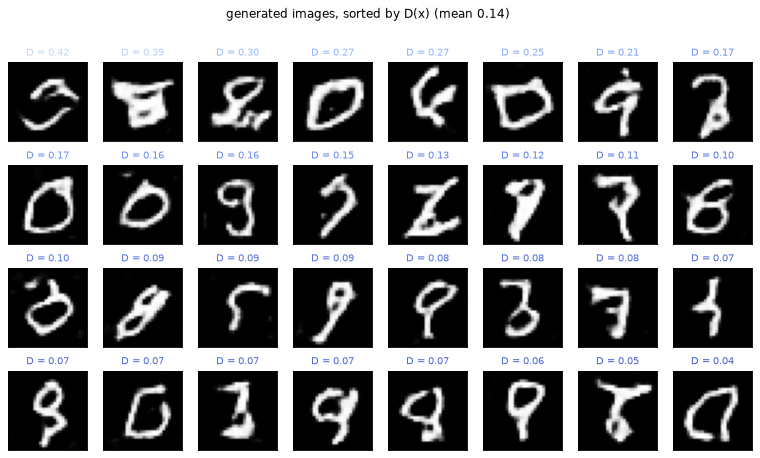

HTML(value='<b>3.1 real images sorted by D</b>')

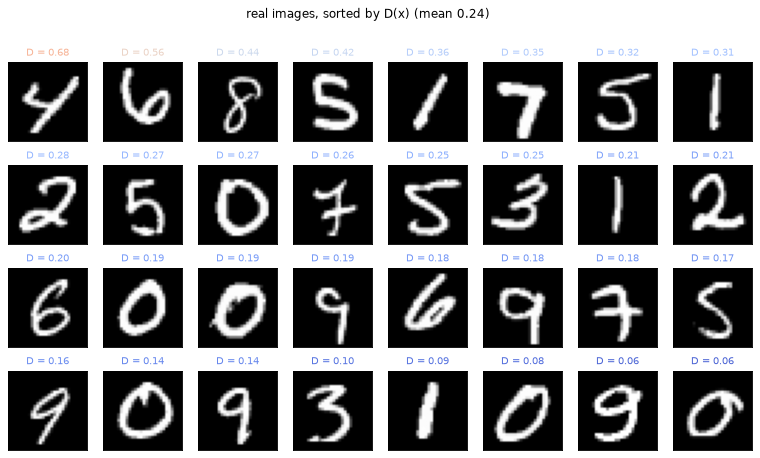

HTML(value='<b>3.2 linear interpolation, seeds 1 -> 2</b>')

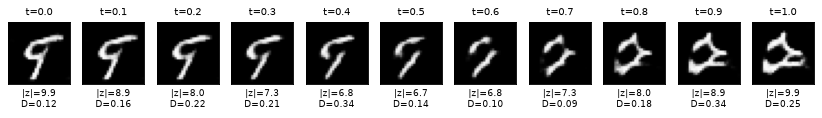

HTML(value='<b>3.2 linear interpolation, seeds 10 -> 20</b>')

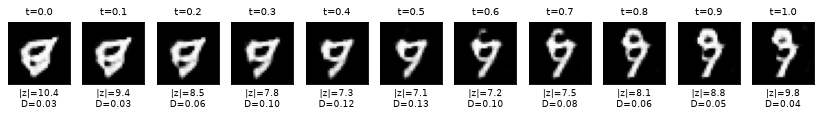

HTML(value='<b>3.2 spherical (slerp) interpolation, seeds 1 -> 2</b>')

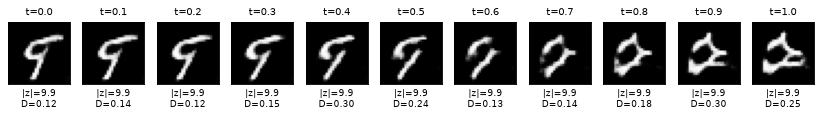

HTML(value='<b>3.2 spherical (slerp) interpolation, seeds 10 -> 20</b>')

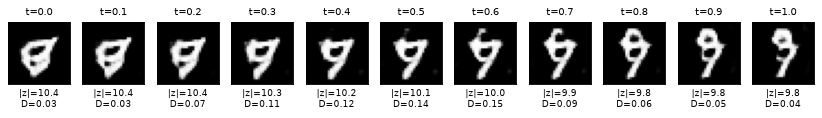

dimensions with the largest effect: [74, 3, 30]  mean |Δpixel|: [0.294, 0.286, 0.28]  median over all dims: 0.201


HTML(value='<b>3.3 dimension 74, r = ±4.0</b>')

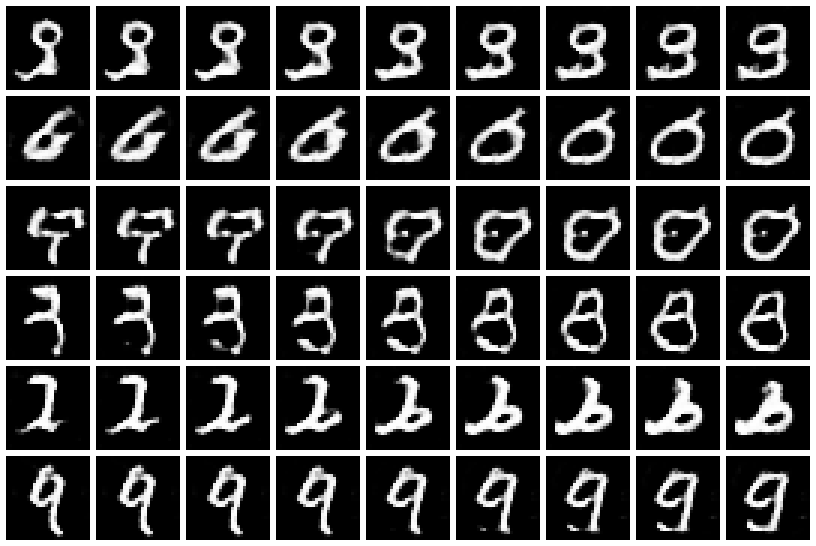

HTML(value='<b>3.3 dimension 3, r = ±4.0</b>')

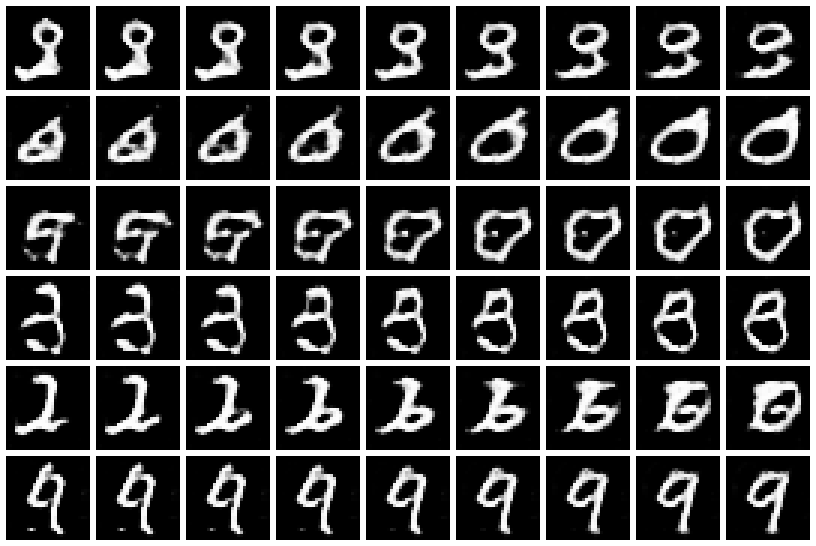

HTML(value='<b>3.3 dimension 74, r = ±10.0</b>')

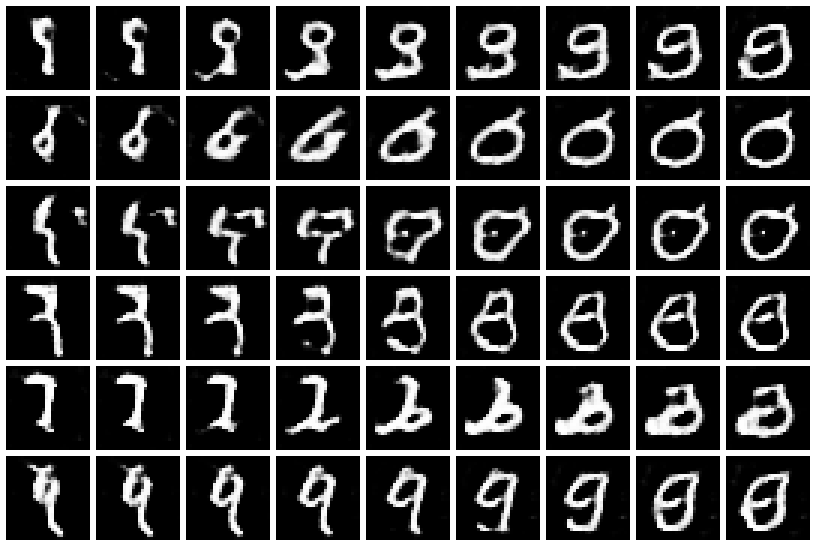

HTML(value='<b>3.4 a + b</b>')

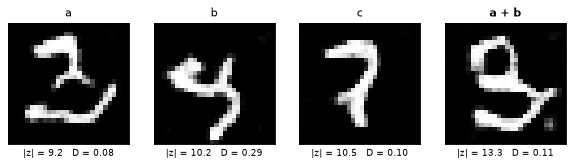

HTML(value='<b>3.4 a + b  (normalised)</b>')

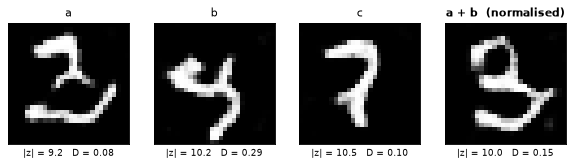

HTML(value='<b>3.4 (a + b) / 2</b>')

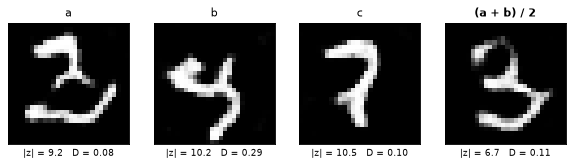

HTML(value='<b>3.4 a − b + c</b>')

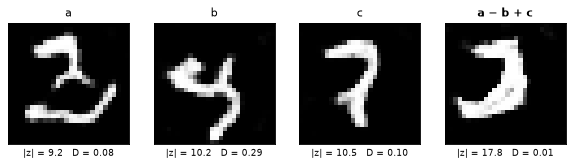

HTML(value='<b>3.4 a − b + c  (normalised)</b>')

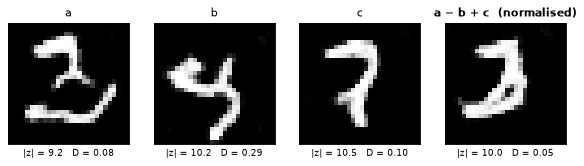

HTML(value='<b>3.4 −a</b>')

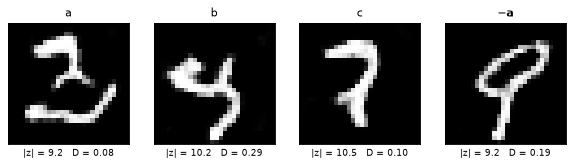

HTML(value='<b>3.5 first k = 0 coordinates frozen to v = 0.0</b>')

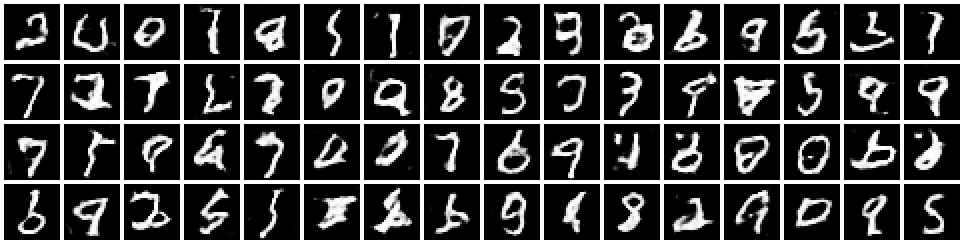

HTML(value='<b>3.5 first k = 20 coordinates frozen to v = 0.0</b>')

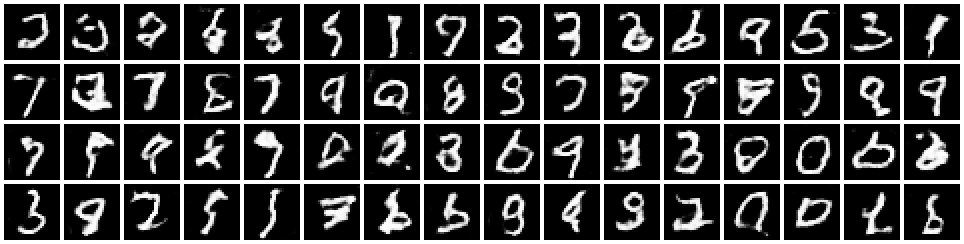

HTML(value='<b>3.5 first k = 50 coordinates frozen to v = 0.0</b>')

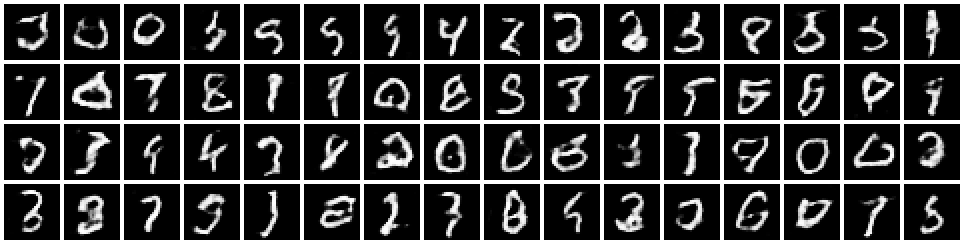

HTML(value='<b>3.5 first k = 80 coordinates frozen to v = 0.0</b>')

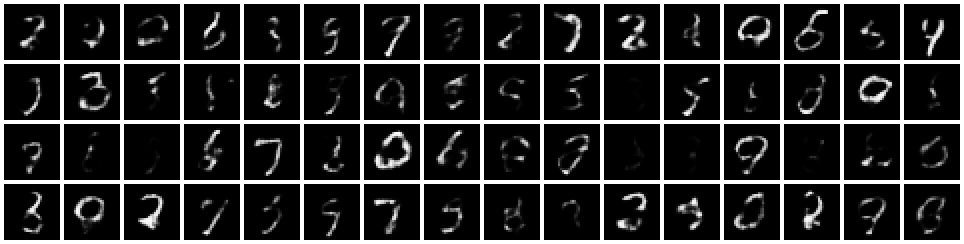

HTML(value='<b>3.5 first k = 100 coordinates frozen to v = 0.0</b>')

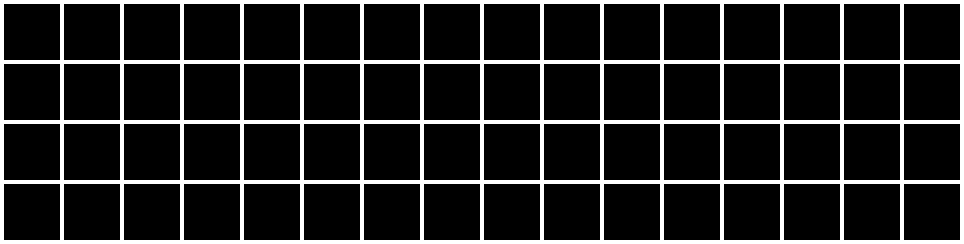

HTML(value='<b>3.5 first k = 50 coordinates frozen to v = 3.0</b>')

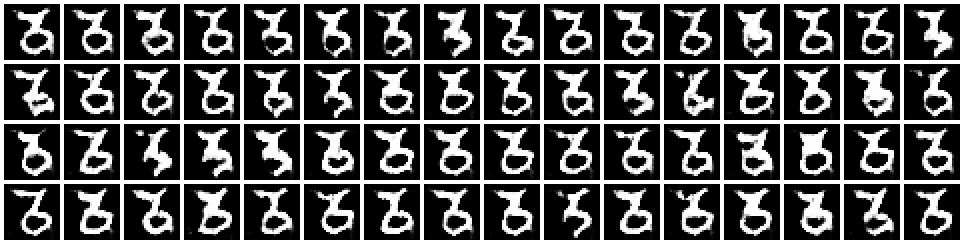

3.5 same z fed 4 times -> max difference between outputs: 1.1920928955078125e-07


HTML(value='<b>3.6 seed 0: block 1 (7x7)</b>')

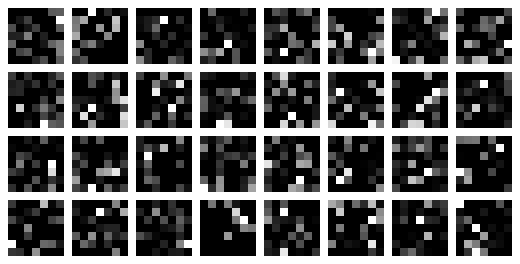

HTML(value='<b>block 2 (14x14)</b>')

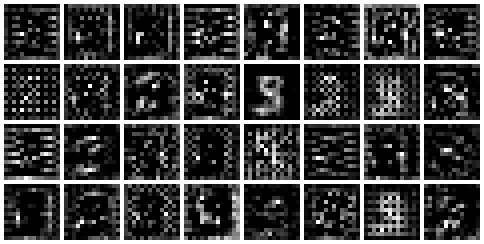

HTML(value='<b>output</b>')

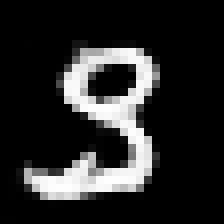

HTML(value='<b>3.6 seed 3: block 1 (7x7)</b>')

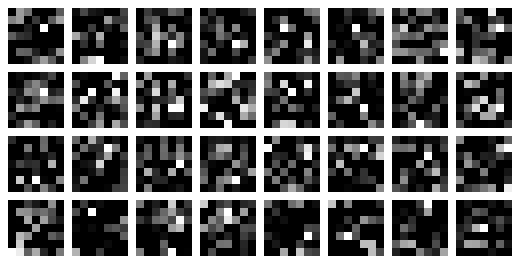

HTML(value='<b>block 2 (14x14)</b>')

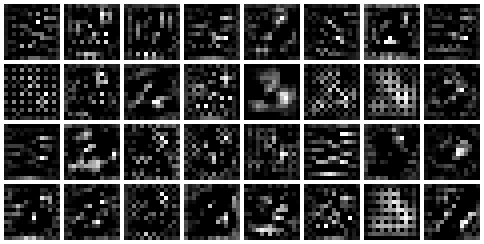

HTML(value='<b>output</b>')

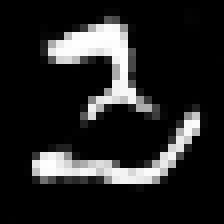

In [30]:
# Static versions of the explorers in Part 3
gal_src.value = "generated"; gal_seed.value = 0; draw_gallery(); show_png(gal_img.value, "3.1 generated images sorted by D")
gal_src.value = "real"; draw_gallery(); show_png(gal_img.value, "3.1 real images sorted by D")
gal_src.value = "generated"

for mode in ["linear", "spherical (slerp)"]:
    int_mode.value = mode
    for a, b in [(1, 2), (10, 20)]:
        int_a.value, int_b.value = a, b
        draw_interp(); show_png(int_img.value, f"3.2 {mode} interpolation, seeds {a} -> {b}")

# 3.3: find the latent dimensions with the largest effect on the image
with torch.no_grad():
    z0 = z_from_seed(0, 16)
    effect = []
    for i in range(NZ):
        zp, zm = z0.clone(), z0.clone(); zp[:, i] = 4; zm[:, i] = -4
        effect.append((generate(zp) - generate(zm)).abs().mean().item())
top = np.argsort(effect)[::-1][:3]
print("dimensions with the largest effect:", top.tolist(), " mean |Δpixel|:", np.round(np.array(effect)[top], 3).tolist(),
      " median over all dims:", round(float(np.median(effect)), 3))
for i, r in [(int(top[0]), 4.0), (int(top[1]), 4.0), (int(top[0]), 10.0)]:
    dim_i.value, dim_r.value = i, r
    draw_dims(); show_png(dim_img.value, f"3.3 dimension {i}, r = ±{r}")

for op in ar_op.options:
    ar_op.value = op
    draw_arith(); show_png(ar_img.value, f"3.4 {op}")

for k, v in [(0, 0.0), (20, 0.0), (50, 0.0), (80, 0.0), (100, 0.0), (50, 3.0)]:
    fx_k.value, fx_v.value = k, v
    draw_freeze(); show_png(fx_img.value, f"3.5 first k = {k} coordinates frozen to v = {v}")
with torch.no_grad():
    z = z_from_seed(5, 4); z[1:] = z[0]
    out = generate(z)
print("3.5 same z fed 4 times -> max difference between outputs:", (out - out[0:1]).abs().max().item())

for s_ in (0, 3):
    in_seed.value = s_
    draw_inside()
    show_png(in_imgs[0].value, f"3.6 seed {s_}: block 1 (7x7)"); show_png(in_imgs[1].value, "block 2 (14x14)"); show_png(in_imgs[2].value, "output")

**Answers (Part 3).**

1. **3.1** Partly. The images with the highest scores are not clearly the best ones, and some clean digits get low scores. The trained $D$ gives low scores to everything: mean 0.14 for generated images but only **0.24 for real images**, and most real digits get $D<0.5$ (in eval mode, with the running BatchNorm statistics). Real images do get higher scores on average, so $D$ ranks them somewhat, but it is **not a good absolute "realism detector"**. $D$ was trained only to separate real data from the *current* generator. It is a moving, relative criterion that drifts with $G$, not a calibrated probability of realism.
2. **3.2** The intermediate images look like **valid digits most of the time**, not like a superposition of two transparent digits: the strokes deform continuously from one digit into the other (e.g. a 9 slowly turns into a distorted 3/8-like shape). The identity switches abruptly in a narrow range of $t$ (around $t\approx0.5$-$0.6$ in seeds 1→2), where the images are less clean. In the **linear** path $\|z\|$ goes down from ≈10 to **≈6.7 in the middle** ($t=0.5$), a region where training $z$'s almost never are; the middle images are thinner/fainter and less digit-like. With **slerp** $\|z\| \approx 9.9$ all along the path and the intermediate images are sharper.
3. **3.3** The dimensions with the largest effect are 74, 3 and 30 (mean pixel change ≈0.29 when going from −4 to +4, compared with a median of 0.20 over all dimensions). For dimension 74 the effect is similar in all rows: going from $-r$ to $+r$ **closes the strokes into loops** (several digits turn into 0/8/9-like shapes), so it acts like a "roundness" factor. But it is **not the same for all rows**: a 2 turns into a "b"-like shape, a 9 barely changes, a 7 becomes a 0... the meaning of a dimension depends on the rest of $z$: the latent space is **entangled**. For large $r$ (±10) the images go out of distribution: strokes become broken or blotchy and some digits turn into strange shapes, since the generator never saw such extreme values.
4. **3.4** No. $G(a+b)$ is **not a mix** of $G(a)$ and $G(b)$: it is just another digit (here a 2 and a 4 give something like an 8/9), with $\|z\| = 13.3$, outside the region seen in training. The normalised version gives almost the same digit (the direction of $z$ matters more than its norm), slightly cleaner. $(a+b)/2$ (norm 6.7, too small) gives yet another, thinner digit (a 3). $a-b+c$ (norm 17.8) gives a thick, blotchy shape that $D$ rejects ($D=0.01$). Its normalised version is a bit better but still not a meaningful combination. $-a$ produces a **completely different digit** (a 9 from a 2), not an "inverted" version of $G(a)$. Vector arithmetic works only along directions that encode attributes, which we haven't identified, so with random vectors it doesn't produce mixtures.
5. **3.5** With $v=0$ the images are still diverse with $k=20$ and even $k=50$-$80$ frozen coordinates. They become fainter/thinner because $\|z\|$ shrinks, but they are still different digits, and they only become identical when **(almost) all 100** coordinates are frozen. Freezing to $v=3$ is very different: with $k=50$ **all 64 images are almost the same digit** (a "6/5"-like shape), because 50 coordinates equal to 3 dominate the vector ($\|z\| \approx 21$) and push it far from the typical set. This shows that the information is **spread over all the latent dimensions** (no small subset decides the image), and that the generator is very sensitive to the *norm* of $z$. For a fixed latent vector the network produces **exactly one output** (we fed the same $z$ four times: maximum difference $1.2\cdot10^{-7}$). $G$ is a **deterministic** function: all the variability comes from $z$, so each input gives a single mode.
6. **3.6** The first block ($7\times7$) encodes the **coarse layout**: each map is a sparse, low-resolution pattern of a few active cells, i.e. *where* things go, with no recognisable strokes. The second block ($14\times14$) encodes the **strokes**: several maps already show the silhouette of the digit or parts of it (oriented segments, curves, the loop of a 9), while others are texture/background detectors with the typical checkerboard pattern of transposed convolutions. The last transposed convolution combines them into the $28\times28$ image.

---
## 4. Diagnosing mode collapse

**Mode collapse** (slides: *A problem of GANs*) means the generator only produces a few of the data's modes. MNIST has 10 obvious modes: the digits. To measure what our GAN produces, we train a small, ordinary **digit classifier** (~30 s, ~98–99 % test accuracy) and use it to label thousands of generated images.

In [31]:
class DigitClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.net(x)

CLF_CKPT = os.path.join(OUT_DIR, "digit_classifier.pt")
clf = DigitClassifier().to(device)
if os.path.exists(CLF_CKPT):
    clf.load_state_dict(torch.load(CLF_CKPT, map_location=device))
else:
    set_seed(0)
    opt = torch.optim.Adam(clf.parameters(), lr=1e-3)
    t0 = time.time()
    for epoch in range(2):
        perm = torch.randperm(X_train.size(0), device=X_train.device)
        for i in range(0, X_train.size(0) - 127, 128):
            idx = perm[i:i + 128]
            loss = F.cross_entropy(clf(X_train[idx]), Y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    torch.save(clf.state_dict(), CLF_CKPT)
    print(f"classifier trained in {time.time() - t0:.0f}s")
clf.eval()
with torch.no_grad():
    acc = (clf(X_test.to(device)).argmax(1).cpu() == Y_test).float().mean().item()
print(f"classifier test accuracy: {100 * acc:.1f}%")

@torch.no_grad()
def classify(x, bs=1000):
    probs = torch.cat([F.softmax(clf(x[i:i + bs]), 1) for i in range(0, len(x), bs)])
    conf, pred = probs.max(1)
    return pred.cpu(), conf.cpu()

classifier trained in 13s


classifier test accuracy: 98.6%


In [32]:
@torch.no_grad()
def mode_report(net, n=5000, seed=0, title="generator", conditional_labels=None):
    set_seed(seed)
    z = torch.randn(n, NZ, device=device)
    x = torch.cat([generate(z[i:i + 1000], None if conditional_labels is None else conditional_labels[i:i + 1000], net=net)
                   for i in range(0, n, 1000)])
    pred, conf = classify(x)
    counts = np.bincount(pred.numpy(), minlength=10) / n
    real_counts = np.bincount(Y_test.numpy(), minlength=10) / len(Y_test)
    fig = Figure(figsize=(12, 3.3)); a1, a2 = fig.subplots(1, 2, gridspec_kw=dict(width_ratios=[1.4, 1]))
    a1.bar(np.arange(10) - 0.2, real_counts, width=0.4, color="gray", label="real test set")
    a1.bar(np.arange(10) + 0.2, counts, width=0.4, color="C1", label=title)
    a1.set_xticks(range(10)); a1.set_xlabel("digit predicted by the classifier"); a1.set_ylabel("fraction")
    a1.set_ylim(0, 1.3 * max(counts.max(), real_counts.max())); a1.legend(loc="upper left", ncol=2)
    a1.set_title(f"Which digits does the {title} produce?")
    a2.hist(conf.numpy(), bins=30, range=(0, 1), color="C1")
    a2.set_title(f"classifier confidence ({100 * (conf < 0.9).float().mean():.0f}% below 0.9)"); a2.set_xlabel("max class probability")
    return fig_to_png(fig), x, pred, conf

report_png, gen_x, gen_pred, gen_conf = mode_report(G, title="DCGAN")
by_digit = widgets.ToggleButtons(options=list(range(10)), description="digit", style={"button_width": "36px"})
by_order = widgets.ToggleButtons(options=["most confident", "least confident"], description="show")
by_img = widgets.Image(format="png")

def draw_by_digit():
    idx = torch.nonzero(gen_pred == by_digit.value).view(-1)
    if len(idx) == 0:
        by_img.value = tensor_grid_png(torch.full((1, 1, 28, 28), -1.0), nrow=1); return
    order = torch.argsort(gen_conf[idx], descending=by_order.value == "most confident")[:32]
    by_img.value = tensor_grid_png(gen_x[idx[order]], nrow=16, scale=2)

on_change(draw_by_digit, by_digit, by_order)
display(widgets.VBox([widgets.Image(value=report_png, format="png"),
                      widgets.HTML("<b>Generated images the classifier assigns to each digit</b>"),
                      by_digit, by_order, by_img]))

> 🔎 **Questions (Part 4).**
> 1. Are all digits generated about as often as in the real data? Which ones are over- or under-represented? Is this *full* or *partial* mode collapse (or neither)?
> 2. Look at the **least confident** images for a few digits. What do the ambiguous samples look like? (Compare with the "trails" between clusters in Part 1, preset ①.)
> 3. The classifier only checks *which* digit is drawn. Could a GAN pass this test and still have collapsed in a subtler way (e.g. every "7" drawn identically)? How would you check?

### 4.1 *(Optional)* Break it on purpose

Retrain a fresh DCGAN for one epoch with the same imbalance as preset ④ in Part 1: the **generator learns 40× faster than the discriminator** (`lr=2e-3` for $G$, `lr_d=5e-5` for $D$). Watch the dashboard, then compare its digit histogram and samples with the DCGAN above. Afterwards, try other settings: equal learning rates of `2e-3`, `beta1=0.9`, or one-sided label smoothing (`real_label=0.9`, a *ganhacks* trick). One run takes about one fifth of the training time in Part 2.

HTML(value='<b>4. digit histogram of 5000 DCGAN samples</b>')

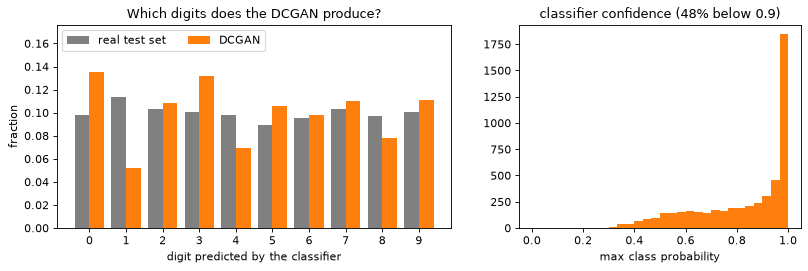

digit 0: generated  13.6%   real   9.8%   mean confidence 0.90
digit 1: generated   5.2%   real  11.3%   mean confidence 0.82
digit 2: generated  10.9%   real  10.3%   mean confidence 0.83
digit 3: generated  13.1%   real  10.1%   mean confidence 0.82
digit 4: generated   6.9%   real   9.8%   mean confidence 0.80
digit 5: generated  10.5%   real   8.9%   mean confidence 0.84
digit 6: generated   9.8%   real   9.6%   mean confidence 0.81
digit 7: generated  11.0%   real  10.3%   mean confidence 0.86
digit 8: generated   7.8%   real   9.7%   mean confidence 0.79
digit 9: generated  11.1%   real  10.1%   mean confidence 0.80


HTML(value='<b>least confident samples classified as 1</b>')

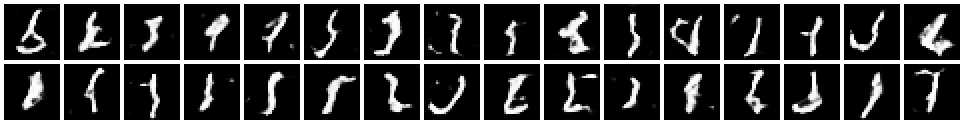

HTML(value='<b>least confident samples classified as 4</b>')

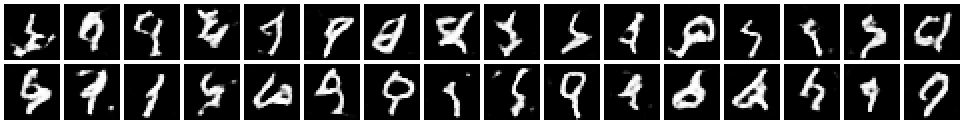

HTML(value='<b>least confident samples classified as 8</b>')

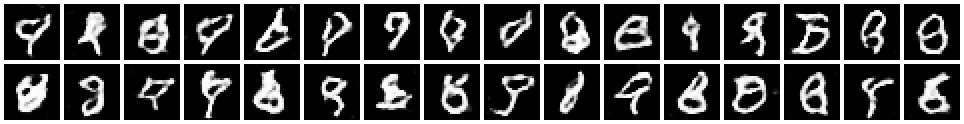

HTML(value='<b>least confident samples classified as 9</b>')

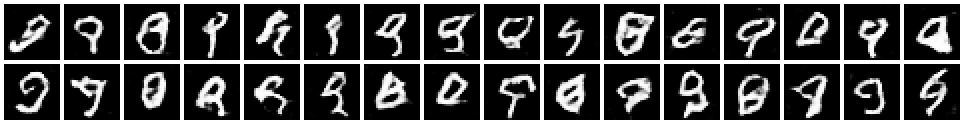

HTML(value='<b>most confident samples classified as 1</b>')

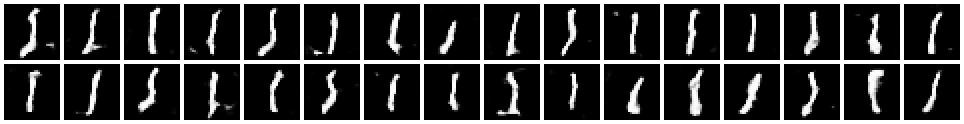

HTML(value='<b>most confident samples classified as 7</b>')

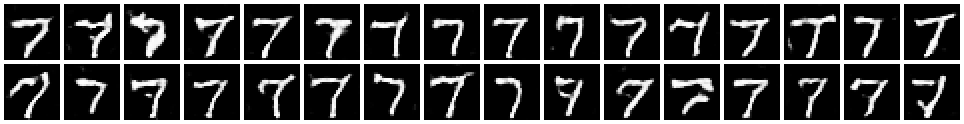

In [33]:
show_png(report_png, "4. digit histogram of 5000 DCGAN samples")
counts = np.bincount(gen_pred.numpy(), minlength=10) / len(gen_pred)
real_counts = np.bincount(Y_test.numpy(), minlength=10) / len(Y_test)
for d in range(10):
    print(f"digit {d}: generated {100 * counts[d]:5.1f}%   real {100 * real_counts[d]:5.1f}%   "
          f"mean confidence {gen_conf[gen_pred == d].mean().item():.2f}")
by_order.value = "least confident"
for d in (1, 4, 8, 9):
    by_digit.value = d; draw_by_digit(); show_png(by_img.value, f"least confident samples classified as {d}")
by_order.value = "most confident"
for d in (1, 7):
    by_digit.value = d; draw_by_digit(); show_png(by_img.value, f"most confident samples classified as {d}")

**Answers (Part 4).**

1. **Roughly yes**: all 10 digits are generated, with frequencies between 5 % and 14 % (real: 9-11 %). **Over-represented:** 0 (13.6 % vs 9.8 %) and 3 (13.1 % vs 10.1 %). **Under-represented:** 1 (5.2 % vs 11.3 %, less than half), 4 (6.9 % vs 9.8 %) and 8 (7.8 % vs 9.7 %). So there is **no full mode collapse**, only a **mild partial imbalance**: some modes are less covered than others. The "1" is a thin, simple stroke that the discriminator easily recognises, and the generator seems to prefer more "ink".
2. The least confident samples are **ambiguous shapes halfway between two digits**, plus some broken or incomplete strokes. Concretely: for "1" they are curved or broken strokes closer to a 7, 3 or 5; for "4" shapes between 4, 9 and 7; for "8" and "9" loops that could be 8, 9, 6 or 0. They are the image equivalent of the **trails between clusters** in Part 1 ①: $G$ is continuous, so the $z$'s that lie between the regions mapped to two different digits produce images that morph from one digit into the other. The classifier confidence reflects this: the mean confidence is only 0.79-0.90 per class, and many samples are below 0.9.
3. **Yes.** A GAN could produce all 10 digits in the right proportions and still have **collapsed within each class**, e.g. every "7" drawn identically (same slant, thickness, size). The classifier would not notice. To check it: compute the diversity *within* each predicted class (pairwise distances between samples, or between their features in a pretrained network, compared with the same quantity for real images); look for near-duplicates (nearest neighbour of each sample among the others); compare feature statistics with the real data (FID per class, precision/recall for generative models); or simply visualise many samples per class, as in the widget above.

In [34]:
RUN_BAD_EXPERIMENT = True      # set to True to run

if RUN_BAD_EXPERIMENT:
    set_seed(1)
    G_bad = Generator().to(device); G_bad.apply(weights_init)
    D_bad = Discriminator().to(device); D_bad.apply(weights_init)
    bad_hist, bad_frames = train_gan_mnist(G_bad, D_bad, epochs=1, lr=2e-3, lr_d=5e-5, title="bad DCGAN")
    png, *_ = mode_report(G_bad, title="bad DCGAN")
    samples = tensor_grid_png(generate(torch.randn(64, NZ, device=device), net=G_bad), nrow=16, scale=2)
    display(widgets.VBox([widgets.Image(value=png, format="png"),
                          cap("64 samples from 64 different z's", widgets.Image(value=samples, format="png"))]))

bad DCGAN digit distribution (%): [9.7, 0.0, 9.6, 48.9, 4.0, 6.6, 2.5, 0.7, 12.8, 5.3]


HTML(value='<b>bad DCGAN: last dashboard frame</b>')

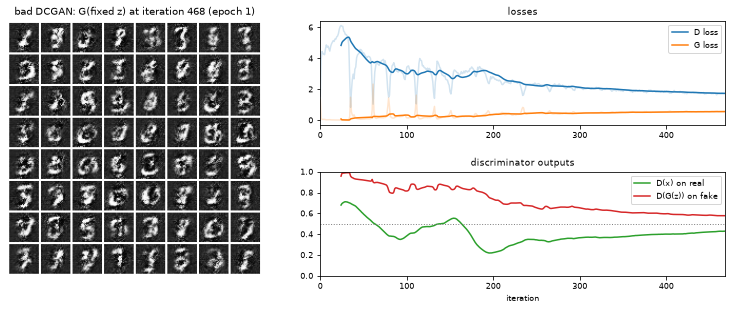

In [35]:
bad_counts = np.bincount(mode_report(G_bad, title="bad DCGAN")[2].numpy(), minlength=10) / 5000
print("bad DCGAN digit distribution (%):", np.round(100 * bad_counts, 1).tolist())
show_png(bad_frames[-1], "bad DCGAN: last dashboard frame")

**4.1 Result.** With the generator learning 40× faster than the discriminator (lr G = 2e-3, lr D = 5e-5) and 1 epoch, the training is clearly broken. $D(G(z))$ is **higher than $D(x)$ almost all the time** (≈0.6-0.9 vs ≈0.3-0.5): the slow discriminator can't follow the generator and ends up calling the fakes more real than the real images. The D loss stays high (2-5) and the G loss near 0. The samples are noisy, blotchy digits with a textured background, and the digit histogram is very unbalanced: **48.9 % of the samples are classified as "3"**, 12.8 % as 8, almost no 1s (0.0 %) or 7s (0.7 %). This is **partial mode collapse**, the image version of preset ④ in Part 1, compared with the reasonably balanced histogram of the properly trained DCGAN.

---
## 5. *(Optional)* Conditional GAN

In a plain GAN we cannot choose *which* digit comes out. A **conditional GAN** (slides: *Conditional GAN*) gives the label $y$ to both players: $G(z, y)$ and $D(x, y)$. Our classes already support it: $G$ concatenates a one-hot $y$ to $z$, and $D$ receives $y$ as 10 extra constant image channels. Now $D$ must also reject *real-looking images of the wrong digit*, so $G$ is forced to follow the label.

During training, each **row** of the dashboard grid uses one fixed $z$ and each **column** asks for one digit.

In [36]:
CGAN_EPOCHS = 3
CGAN_CKPT = os.path.join(OUT_DIR, "cgan_mnist.pt")
set_seed(0)
cG = Generator(n_classes=10).to(device); cG.apply(weights_init)
cD = Discriminator(n_classes=10).to(device); cD.apply(weights_init)
if os.path.exists(CGAN_CKPT) and not RETRAIN:
    cgan_hist, cgan_frames = load_ckpt(CGAN_CKPT, cG, cD)
    print(f"Loaded the trained conditional GAN from {CGAN_CKPT}.")
    display(widgets.Image(value=cgan_frames[-1], format="png"))
else:
    cgan_hist, cgan_frames = train_gan_mnist(cG, cD, epochs=CGAN_EPOCHS, conditional=True, title="cGAN")
    save_ckpt(CGAN_CKPT, cG, cD, cgan_hist, cgan_frames)

Now **you** choose. Left: the same latent vectors $z$ (rows) rendered as every digit (columns): what stays the same along a row? Right: many different $z$'s for the digit you select. Below: does the classifier agree with the label we asked for?

In [37]:
cg_seed = widgets.IntSlider(value=0, min=0, max=500, description="seeds from", layout=widgets.Layout(width="450px"))
cg_digit = widgets.ToggleButtons(options=list(range(10)), value=7, description="digit", style={"button_width": "36px"})
cg_left, cg_right = widgets.Image(format="png"), widgets.Image(format="png")

@torch.no_grad()
def draw_cgan():
    rows = 6
    z = z_from_seed(cg_seed.value, rows).repeat_interleave(10, 0)
    y = torch.arange(10, device=device).repeat(rows)
    cg_left.value = tensor_grid_png(generate(z, y, net=cG), nrow=10, scale=2)
    z2 = z_from_seed(1000 + cg_seed.value, 48)
    y2 = torch.full((48,), cg_digit.value, device=device, dtype=torch.long)
    cg_right.value = tensor_grid_png(generate(z2, y2, net=cG), nrow=8, scale=2)

on_change(draw_cgan, cg_seed, cg_digit)

y_req = torch.arange(10, device=device).repeat(500)
cg_png, _, cg_pred, _ = mode_report(cG, n=5000, title="cGAN", conditional_labels=y_req)
cg_acc = (cg_pred == y_req.cpu()).float().mean().item()
display(widgets.VBox([widgets.HBox([cg_seed, cg_digit]),
                      widgets.HBox([cap("same z (rows) × every digit (columns)", cg_left),
                                    cap("many z's for the selected digit", cg_right)]),
                      widgets.HTML(f"<b>Classifier agrees with the requested digit for {100 * cg_acc:.1f}% of 5000 samples.</b>"),
                      widgets.Image(value=cg_png, format="png")]))

HTML(value='<b>same z (rows) x every digit (columns)</b>')

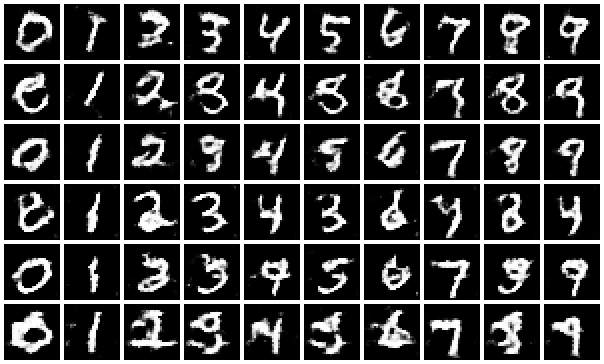

HTML(value="<b>48 different z's for digit 7</b>")

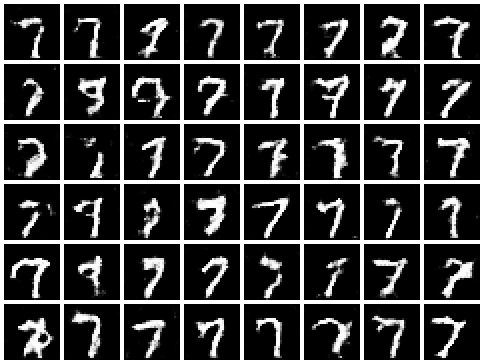

HTML(value='<b>cGAN digit histogram</b>')

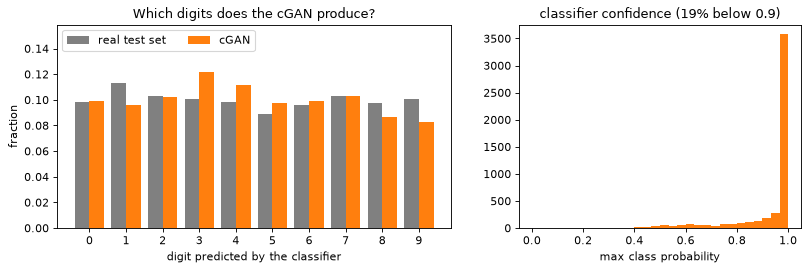

classifier agrees with the requested digit for 89.9% of 5000 samples


In [38]:
draw_cgan()
show_png(cg_left.value, "same z (rows) x every digit (columns)")
show_png(cg_right.value, f"48 different z's for digit {cg_digit.value}")
show_png(cg_png, "cGAN digit histogram")
print(f"classifier agrees with the requested digit for {100 * cg_acc:.1f}% of 5000 samples")

> 🔎 **Questions (Part 5).**
> 1. Along a row (same $z$, different $y$), what is shared between the digits? So what does $z$ encode once the label is given?
> 2. Compare the digit histogram with the unconditional DCGAN in Part 4. Why does conditioning help against mode collapse?
> 3. How would you modify this setup to control *two* attributes (e.g. digit and thickness)?

---
## Wrap-up

- A GAN learns an **implicit** density: you can sample from it but you can't evaluate $p_g(x)$.
- Training is a **two-player game**, not a minimisation: losses oscillate, and their values say little about sample quality.
- The **non-saturating** generator loss avoids vanishing gradients when $D$ is winning.
- Typical failures: **mode collapse**, **vanishing gradients**, **non-convergence**. WGAN(-GP), conditioning, and architectural tricks (DCGAN guidelines, spectral norm, minibatch discrimination...) all help.
- The latent space is smooth but **entangled**; StyleGAN's mapping network was designed to fix that.

**Answers (Part 5).**

1. Along a row (same $z$, different $y$) the digits share the **style**: stroke thickness, slant, size, roundness, and the "handwriting" in general (e.g. a row with thick, slanted digits keeps them thick and slanted for every class). So, once the label is given, $z$ encodes **everything except the digit identity**: the style/nuisance factors. The class information comes from $y$.
2. The conditional GAN generates the requested digit in **89.9 %** of the 5000 samples (classifier agreement), so the digit histogram follows the requested uniform distribution (500 samples of each class), while the unconditional DCGAN of Part 4 under-generated 1s, 4s and 8s and over-generated 0s and 3s. Conditioning helps against mode collapse because **the modes are made explicit**: the labels are sampled uniformly, so $G$ is forced to produce every class, and $D$ also rejects a real-looking image of the wrong digit. $G$ can't "drop" a mode without being penalised by $D$ for that label.
3. Add a second conditioning variable. Concatenate a second code to $z$ in $G$ and as extra input channels in $D$: a one-hot vector for a discrete attribute, or a scalar/normalised value for a continuous one like thickness. This requires labels for that attribute in the training data. For MNIST they could be computed automatically (e.g. thickness = number of ink pixels / skeleton length). Alternatives: a projection discriminator / auxiliary classifier (AC-GAN) that predicts both attributes; or, without labels, InfoGAN, which learns latent codes that maximise mutual information with the output and usually discovers digit class, slant and thickness on its own.